# Module 1 — Task 2: Predict initiative success

**Brief (verbatim):**
> **Task 2: Predict initiative success**
> Target: Historical_Success
> Compare models to model target variable and compare their performance detailing explainability (which characteristics make an initiative more likely to succeed).

**Where this sits in the chain:** Data → **ML Prediction** → Financial Metric → Risk Assessment → Business Decision. This task produces **P(Success)**, the predicted probability that each initiative succeeds. Task 3 multiplies it by NPV (Net Present Value: today's value of the cash a project brings in, minus what it costs) to get Expected NPV.

**How this notebook is laid out:** each step has a plain explanation (with formulas), then the commented code, then its table or chart.

| Step | What it does |
| --- | --- |
| 0 | Setup |
| 1 | Data and the 26 inputs |
| 2 | Cross-validation: how every model is trained and tested |
| 3 | Preparation and the seven models |
| 4 | Measures (formulas) |
| 5 | Run the comparison (25 rounds per model) |
| 5b | Overfitting check: training rows against test rows |
| 6 | Comparison chart |
| 7 | What balancing would have done (comparison only) |
| 8 | Choose the model for Task 3 |
| 8b | Why lasso and not the others: ML and finance scorecard |
| 8c | In rupees: how much failed capital each model's flag would have caught |
| 9 | Better than luck? (shuffled-label check) |
| 10 | Explainability: which characteristics raise success |
| 10b-ii | How lasso works inside: how it chooses, ranks and switches off inputs |
| 10e | What drives success: one ranked table, with the finance meaning |
| 11 | Are the probabilities right? (reliability) |
| 12 | Save P(Success) for Task 3 |
| 13 | What the results say: ML case, finance case, decision |

**Decisions used:**
- M1-07 / M1-18: repeated stratified 5-fold cross-validation;
- M1-14: fixed settings;
- M1-15: no balancing;
- M1-16: choose by Brier score plus finance checks;
- M1-17: 26 inputs plus lasso.

All are in `docs/decisions.md`.

**Runs on its own or from `run_module_1.ipynb`.** It loads everything it needs itself.

**Helpers used:**
- `helpers/m01_data.py`: data plus derived columns;
- `helpers/m01_style.py`: chart style.

## 0. Setup

Works locally and in Google Colab.
- **Colab:** upload the whole unzipped project folder (any name) to Google Drive; the cell below finds it. Then run all cells.
- The full run takes about 19 minutes, because each of the 7 models is trained 25 times and lasso also runs an inner cross-validation.

In [1]:
import os
import sys
import json
import warnings
from pathlib import Path

# ---- Find the project folder: any folder name works, on your computer or in Google Colab ----
# The project folder is the one holding run_novafin.ipynb and data/.
IN_COLAB = "google.colab" in sys.modules
is_project = lambda p: (p / "run_novafin.ipynb").exists() and (p / "data").is_dir()
places = [p for p in [Path.cwd(), *Path.cwd().parents] if is_project(p)]
if IN_COLAB and not places:                                 # Colab starts outside the project: look in /content, then in Google Drive
    for base in [Path("/content"), Path("/content/drive/MyDrive")]:
        if "drive" in base.parts:
            from google.colab import drive
            drive.mount("/content/drive")                   # asks for access to your Google Drive
        for depth in ["", "*/", "*/*/", "*/*/*/"]:
            places += [f.parent for f in sorted(base.glob(depth + "run_novafin.ipynb")) if is_project(f.parent)]
        if places:
            break
if not places:
    raise FileNotFoundError("Project folder not found: unzip the whole project and keep run_novafin.ipynb, data/ and the module folders together (see HOW_TO_RUN.md).")
PROJECT_ROOT = places[0]

MODULE_DIR = PROJECT_ROOT / "module_01_corporate_finance"
OUT_DIR = MODULE_DIR / "outputs" / "task2"            # tables, charts and P(Success) for Task 3
OUT_DIR.mkdir(parents=True, exist_ok=True)
sys.path.insert(0, str(MODULE_DIR / "helpers"))       # make the Module 1 helpers importable

# ---- Quieter output ----------------------------------------------------------------------
os.environ.setdefault("LOKY_MAX_CPU_COUNT", "4")      # avoids a Windows CPU-count warning from joblib
warnings.filterwarnings("ignore", category=UserWarning)
warnings.filterwarnings("ignore", category=FutureWarning)

# ---- Libraries ---------------------------------------------------------------------------
import numpy as np                    # maths on arrays
import pandas as pd                   # tables
import matplotlib.pyplot as plt       # charts
import shap                           # SHAP explanations (step 10)

# scikit-learn: the standard Python machine-learning library
from sklearn.pipeline import Pipeline                         # chains preparation + model so both are fitted together
from sklearn.compose import ColumnTransformer                  # applies different preparation to different columns
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.model_selection import RepeatedStratifiedKFold, StratifiedKFold, permutation_test_score
from sklearn.dummy import DummyClassifier                      # the "always the base rate" baseline
from sklearn.linear_model import LogisticRegression, LogisticRegressionCV
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.utils.class_weight import compute_sample_weight   # only for the balancing comparison (step 7)
from sklearn.metrics import (roc_auc_score, brier_score_loss, log_loss, accuracy_score,
                             precision_score, recall_score, f1_score)
from xgboost import XGBClassifier                              # gradient boosting (XGBoost library)
from lightgbm import LGBMClassifier                            # gradient boosting (LightGBM library)

# ---- Module 1 helpers --------------------------------------------------------------------
from m01_data import load_initiatives_with_features, DERIVED_COLUMNS
from m01_style import apply_style, SURFACE, INK, INK_2, GRID, BLUE, ORANGE, AQUA
apply_style()

SEED = 42                             # one fixed random seed everywhere (project decision P-06)
pd.set_option("display.width", 200, "display.max_columns", 30)


def save_table(table: pd.DataFrame, name: str, keep_index: bool = False) -> None:
    """Save a table to outputs/task2/<name>.csv."""
    table.to_csv(OUT_DIR / f"{name}.csv", index=keep_index)


def save_chart(fig, name: str) -> None:
    """Save a chart to outputs/task2/<name>.png at print quality."""
    fig.savefig(OUT_DIR / f"{name}.png", dpi=150, bbox_inches="tight")


print("Project folder found")
print("Outputs go to: ", OUT_DIR.relative_to(PROJECT_ROOT).as_posix())

Project folder found
Outputs go to:  module_01_corporate_finance/outputs/task2


## 1. Data and the 26 inputs

**Target:** `Historical_Success`, where 1 = succeeded and 0 = failed.

```text
Base rate    = successes ÷ initiatives = 138 ÷ 180 = 0.767  (77%)
Failure rate = 42 ÷ 180 = 0.233  (23%)
```

**Inputs: 26 columns, fixed before any modelling** (decision M1-17):

| Group | Columns | Count |
| --- | --- | --- |
| Given numbers | Initial_Investment, Revenue_Year1, Revenue_Year2, Revenue_Year3, Operating_Cost, Expected_ROI, Business_Growth, GDP_Growth, Interest_Rate, Competition_Index | 10 |
| Derived numbers (`DERIVED_COLUMNS` in `helpers/m01_data.py`) | CF1, CF2, CF3, NPV_3yr, Revenue_Growth_Y1_Y3, Cash_Return_Pct, ROI_Spread | 7 |
| Business_Unit | 6 units, one 0/1 column each (one-hot encoding, step 3) | 6 |
| Risk_Rating | Low, Medium, High, one 0/1 column each | 3 |

Left out: Initiative_ID (only a label) and Historical_Success (the answer).

All derived columns are row-by-row arithmetic on each initiative's own numbers, and none uses the answer, so they cannot leak (decision P-19).

In [2]:
# Load the data and add the derived columns (shared helper, same as Task 1).
df = load_initiatives_with_features()

# The 10 given number columns, in the brief's order.
NUM_GIVEN = ["Initial_Investment", "Revenue_Year1", "Revenue_Year2", "Revenue_Year3", "Operating_Cost",
             "Expected_ROI", "Business_Growth", "GDP_Growth", "Interest_Rate", "Competition_Index"]
# The 7 derived number columns, taken from the documented list in the helper.
NUM_DERIVED = list(DERIVED_COLUMNS)
NUM_COLS = NUM_GIVEN + NUM_DERIVED                      # 17 number columns
CAT_COLS = ["Business_Unit", "Risk_Rating"]             # 2 label columns → 6 + 3 = 9 one-hot columns

X = df[NUM_COLS + CAT_COLS]                             # model inputs (before one-hot encoding)
y = df["Historical_Success"].to_numpy()                 # target as a 0/1 array
ids = df["Initiative_ID"].to_numpy()                    # kept aside to label the saved predictions

n_one_hot = df["Business_Unit"].nunique() + df["Risk_Rating"].nunique()
print(f"Initiatives: {len(df)} | successes: {y.sum()} | failures: {(y == 0).sum()} | base rate: {y.mean():.3f}")
print(f"Inputs: {len(NUM_GIVEN)} given + {len(NUM_DERIVED)} derived numbers + {n_one_hot} one-hot columns "
      f"= {len(NUM_COLS) + n_one_hot}")
display(pd.DataFrame({"Derived column": list(DERIVED_COLUMNS), "Formula": list(DERIVED_COLUMNS.values())}))

Initiatives: 180 | successes: 138 | failures: 42 | base rate: 0.767
Inputs: 10 given + 7 derived numbers + 9 one-hot columns = 26


,Derived column,Formula
0,CF1,Revenue_Year1 − Operating_Cost (₹ lakh)
1,CF2,Revenue_Year2 − Operating_Cost (₹ lakh)
2,CF3,Revenue_Year3 − Operating_Cost (₹ lakh)
3,NPV_3yr,−Initial_Investment + CF1/(1 + r) + CF2/(1 + r...
4,Revenue_Growth_Y1_Y3,(Revenue_Year3 ÷ Revenue_Year1 − 1) × 100 (%)
5,Cash_Return_Pct,"average(CF1, CF2, CF3) ÷ Initial_Investment × ..."
6,ROI_Spread,Expected_ROI − Interest_Rate (% points; above...


## 2. Cross-validation: how every model is trained and tested

**The problem.** To know how a model will do on *new* initiatives, we must test it on rows it did not learn from.
- A single 80/20 split leaves only 36 test initiatives, about 8 of them failures.
- One failure more or less in that test set moves recall by about 12 points, so the score would depend on luck.

**Repeated stratified 5-fold cross-validation** (decisions M1-07, M1-18):

```text
1. Shuffle the 180 initiatives and cut them into 5 folds of 36.
2. Round 1: train on folds 2–5 (144 rows), test on fold 1 (36 rows); round 2: test on fold 2; … round 5.
3. Every initiative is tested once, by a model that never saw it.
4. Repeat steps 1–3 five times with different shuffles  →  5 × 5 = 25 rounds per model.
```

- **Stratified:** every fold keeps the 77/23 mix (about 28 successes and 8 failures).
- **Same 25 rounds for every model:** the seed is fixed, so the comparison is fair (paired). No model gets an easier test set.
- **We report** the mean over the 25 rounds (typical performance) and the standard deviation (how much it depends on luck).
- **Out-of-fold predictions:** in each repeat, every initiative is predicted once, when it is a test row. Averaging its 5 predictions gives its P(Success) for Task 3.
- **No leakage:** everything that learns from data (scaling, one-hot columns, lasso's penalty) is learned on the 144 training rows only, inside a Pipeline (step 3).

The table below shows the first repeat's 5 rounds, to see the stratification at work.

In [3]:
# RepeatedStratifiedKFold produces the 25 (train rows, test rows) pairs.
#   n_splits=5   → 5 folds per repeat
#   n_repeats=5  → 5 repeats with different shuffles
#   random_state → fixed seed, so every model gets exactly the same 25 splits
N_SPLITS, N_REPEATS = 5, 5
cv = RepeatedStratifiedKFold(n_splits=N_SPLITS, n_repeats=N_REPEATS, random_state=SEED)
SPLITS = list(cv.split(X, y))          # store once and reuse for every model (identical rounds)

# Show the first repeat: sizes and how many failures land in each test fold.
rows = []
for r, (tr, te) in enumerate(SPLITS[:N_SPLITS], start=1):
    rows.append({"Round": r, "Train rows": len(tr), "Test rows": len(te),
                 "Failures in test": int((y[te] == 0).sum()),
                 "Success rate in train": round(y[tr].mean(), 3)})
display(pd.DataFrame(rows))
print(f"Total rounds per model: {len(SPLITS)}")

,Round,Train rows,Test rows,Failures in test,Success rate in train
0,1,144,36,8,0.764
1,2,144,36,8,0.764
2,3,144,36,8,0.764
3,4,144,36,9,0.771
4,5,144,36,9,0.771


Total rounds per model: 25


## 3. Preparation and the seven models

**Preparation (inside each round, learned on the 144 training rows only):**

```text
Scaling (for logistic regression and lasso only):   z = (x − mean) ÷ standard deviation
    → every number column gets mean 0 and spread 1, so weights are comparable and the penalty treats inputs fairly.
One-hot encoding (all models):  Risk_Rating = "Low"  →  Low = 1, Medium = 0, High = 0
```

Trees don't need scaling: they only ask "is x above a threshold?", which scaling doesn't change.

A **Pipeline** chains preparation and model, so `fit` learns both from the training rows and `predict` applies both to the test rows. This is what prevents leakage.

**The seven models.** All are unweighted (M1-15) with fixed settings (M1-14).

| Model | What it is | Settings |
| --- | --- | --- |
| Baseline | Predicts the training base rate (about 0.77) for everyone; the score to beat | — |
| Logistic regression | P = 1 ÷ (1 + e^−(b0 + b1·x1 + … + bk·xk)); weights b learned by minimising log-loss + a small ridge penalty λ·Σb² | C = 1 (scikit-learn writes the penalty as C = 1 ÷ λ) |
| Lasso logistic regression | Same, but the penalty is λ·Σ\|b\|, which sets weak weights to exactly 0, so the model keeps only useful inputs | λ chosen by an inner 5-fold CV on the 144 training rows (10 values, best Brier): nested cross-validation |
| Decision tree | A flowchart of yes/no questions; each leaf predicts its share of successes | Depth ≤ 3, ≥ 10 rows per leaf |
| Random forest | 300 trees on random resamples of rows and inputs; their predictions are averaged | Depth ≤ 4, ≥ 5 rows per leaf |
| XGBoost | 200 small trees built one after another, each fitted to the remaining errors and added with weight 0.05 | Depth 2; 80% of rows and inputs per tree |
| LightGBM | Same idea, another implementation | Depth 2, 4 leaves, ≥ 10 rows per leaf |

In [4]:
def make_preparation(scale: bool) -> ColumnTransformer:
    """Build the preparation step for one model.

    scale=True  → number columns are standardised (z = (x − mean) ÷ std): needed by
                  logistic regression and lasso, whose penalty compares weight sizes.
    scale=False → number columns pass through unchanged (trees do not need scaling).
    Label columns are always one-hot encoded (one 0/1 column per category).
    Nothing is learned here yet: mean, std and category lists are learned when the
    Pipeline is fitted, i.e. on the training rows of each round only.
    """
    number_step = StandardScaler() if scale else "passthrough"
    return ColumnTransformer([
        ("num", number_step, NUM_COLS),                                         # 17 number columns
        ("cat", OneHotEncoder(handle_unknown="ignore", sparse_output=False), CAT_COLS),  # 9 one-hot columns
    ])


def make_models() -> dict:
    """Return the seven models, each as a Pipeline (preparation → model), all unweighted.

    The order goes from simplest to most complex; step 8 uses it to prefer the simpler
    model when two are equally good (decision M1-16).
    """
    return {
        # 1. Baseline: always predicts the training rows' success rate ("prior").
        "Baseline": Pipeline([("prep", make_preparation(False)),
                              ("model", DummyClassifier(strategy="prior"))]),
        # 2. Lasso: L1 penalty; LogisticRegressionCV runs the inner 5-fold CV on the training
        #    rows to choose among 10 penalty values (Cs=10), scoring each by Brier score.
        #    solver="liblinear" is a solver that supports the L1 penalty.
        "Lasso": Pipeline([("prep", make_preparation(True)),
                           ("model", LogisticRegressionCV(
                               Cs=10, penalty="l1", solver="liblinear", random_state=SEED,   # fixed seed: liblinear shuffles internally
                               cv=StratifiedKFold(5, shuffle=True, random_state=SEED),
                               scoring="neg_brier_score", max_iter=5000))]),
        # 3. Logistic regression with scikit-learn's default ridge (L2) penalty, C = 1.
        "Logistic regression": Pipeline([("prep", make_preparation(True)),
                                         ("model", LogisticRegression(C=1.0, max_iter=5000))]),
        # 4. Decision tree: shallow (3 questions deep), at least 10 initiatives per final box.
        "Decision tree": Pipeline([("prep", make_preparation(False)),
                                   ("model", DecisionTreeClassifier(max_depth=3, min_samples_leaf=10,
                                                                    random_state=SEED))]),
        # 5. Random forest: 300 shallow trees, averaged.
        "Random forest": Pipeline([("prep", make_preparation(False)),
                                   ("model", RandomForestClassifier(n_estimators=300, max_depth=4,
                                                                    min_samples_leaf=5, random_state=SEED,
                                                                    n_jobs=1))]),
        # 6. XGBoost: 200 depth-2 trees, small learning rate, 80% row/column sampling per tree.
        "XGBoost": Pipeline([("prep", make_preparation(False)),
                             ("model", XGBClassifier(n_estimators=200, max_depth=2, learning_rate=0.05,
                                                     subsample=0.8, colsample_bytree=0.8,
                                                     eval_metric="logloss", random_state=SEED,
                                                     n_jobs=1, verbosity=0))]),
        # 7. LightGBM: same idea; num_leaves=4 matches depth 2; at least 10 rows per leaf.
        "LightGBM": Pipeline([("prep", make_preparation(False)),
                              ("model", LGBMClassifier(n_estimators=200, max_depth=2, num_leaves=4,
                                                       learning_rate=0.05, min_child_samples=10,
                                                       subsample=0.8, subsample_freq=1,
                                                       colsample_bytree=0.8, random_state=SEED,
                                                       n_jobs=1, verbose=-1))]),
    }


MODEL_NAMES = list(make_models())
print("Models:", ", ".join(MODEL_NAMES))

Models: Baseline, Lasso, Logistic regression, Decision tree, Random forest, XGBoost, LightGBM


## 4. Measures (formulas)

We call **failure the "positive" class**, because spotting failures is the point. An initiative is flagged **"at risk"** when P(Success) < cut-off. The cut-off is the training rows' success rate, about 0.77, and asks whether an initiative is less likely to succeed than a typical one (M1-15).

|  | Flagged at risk | Not flagged |
| --- | --- | --- |
| Really failed | TP (failure caught) | FN (failure missed) |
| Really succeeded | FP (good project flagged) | TN (good project passed) |

```text
Accuracy  = (TP + TN) ÷ all                     share labelled correctly (misleading here: "always success" scores 77%)
Precision = TP ÷ (TP + FP)                      of the flagged initiatives, the share that really failed
Recall    = TP ÷ (TP + FN)                      of the real failures, the share flagged
F1        = 2 × Precision × Recall ÷ (Precision + Recall)

ROC-AUC   = share of (failure, success) pairs where the failure gets the lower P(Success); ties count ½
            (0.5 = coin toss, 1.0 = perfect ranking; needs no cut-off)
Brier     = (1 ÷ N) × Σ (pᵢ − yᵢ)²              average squared gap between P(Success) and the outcome (0 = perfect)
Log-loss  = −(1 ÷ N) × Σ [ yᵢ·ln(pᵢ) + (1 − yᵢ)·ln(1 − pᵢ) ]     punishes confident wrong forecasts heavily
```

The **Brier score** decides the model for Task 3, because Expected NPV = P(Success) × NPV uses the probability as a number (M1-16). The baseline's Brier is 0.767 × 0.233 ≈ 0.179, and that's the score to beat.

In [5]:
def score_round(y_true: np.ndarray, p_success: np.ndarray, cutoff: float) -> dict:
    """Score one test fold.

    y_true    : actual outcomes of the test initiatives (1 = success, 0 = failure)
    p_success : predicted P(Success) for the same initiatives
    cutoff    : flag "at risk" when P(Success) < cutoff (the training rows' success rate)
    Returns every measure in a dictionary. For precision/recall/F1 the positive class is
    failure (pos_label=0), because catching failures is the purpose.
    """
    # Turn probabilities into labels: 1 (expected success) if P ≥ cut-off, else 0 (at risk).
    label = (p_success >= cutoff).astype(int)
    return {
        "ROC_AUC": roc_auc_score(y_true, p_success),                     # ranking quality
        "Brier": brier_score_loss(y_true, p_success),                    # probability accuracy
        "Log_loss": log_loss(y_true, np.clip(p_success, 1e-6, 1 - 1e-6), labels=[0, 1]),
        "Accuracy": accuracy_score(y_true, label),
        "Fail_precision": precision_score(y_true, label, pos_label=0, zero_division=0),
        "Fail_recall": recall_score(y_true, label, pos_label=0, zero_division=0),
        "Fail_F1": f1_score(y_true, label, pos_label=0, zero_division=0),
        "Mean_P": p_success.mean(),                                      # average predicted success
    }

## 5. Run the comparison: 7 models × 25 rounds

For each model and each of the 25 rounds, `run_cv`:
1. Fits the Pipeline on the 144 training rows. Lasso also runs its inner 5-fold CV here.
2. Predicts P(Success) for the 36 test rows.
3. Scores them with `score_round`.
4. Stores the predictions as out-of-fold predictions, by repeat.
5. For lasso, records which inputs it kept, to check how stable its choice is.

`weighted=True` is used only in step 7, the balancing comparison.

In [6]:
def clean_name(feature: str) -> str:
    """Make prepared column names readable: 'num__Expected_ROI' → 'Expected_ROI',
    'cat__Risk_Rating_Low' → 'Risk_Rating = Low'."""
    feature = feature.split("__", 1)[1]                     # drop the 'num__' / 'cat__' prefix
    for col in CAT_COLS:                                     # label columns: show as "column = value"
        if feature.startswith(col + "_"):
            return f"{col} = {feature[len(col) + 1:]}"
    return feature


def run_cv(models: dict, weighted: bool = False):
    """Train and test every model on the same 25 rounds.

    Returns
      scores   : one row per (model, round) with every measure from score_round
      oof      : {model: array of shape (5 repeats, 180)} out-of-fold P(Success)
      lasso_kept: one row per round, 1 if lasso kept that input (non-zero weight), else 0
    weighted=True gives each training row a "balanced" weight (failures count about 3.3× a
    success); used only to show the effect of balancing (step 7), never for the decision.
    """
    rows, kept_rows = [], []
    oof = {name: np.full((N_REPEATS, len(y)), np.nan) for name in models}
    for name, pipe in models.items():
        for r, (tr, te) in enumerate(SPLITS):
            repeat = r // N_SPLITS                           # rounds 0–4 → repeat 0, 5–9 → repeat 1, …
            fit_args = {}
            if weighted:
                # "balanced" weight per row = n_rows ÷ (2 × rows in its class), from the TRAINING rows only
                fit_args["model__sample_weight"] = compute_sample_weight("balanced", y[tr])
            pipe.fit(X.iloc[tr], y[tr], **fit_args)          # learn preparation + model on 144 rows
            p = pipe.predict_proba(X.iloc[te])[:, 1]         # column 1 = probability of class 1 (success)
            oof[name][repeat, te] = p                        # store as out-of-fold prediction
            cutoff = y[tr].mean()                            # training base rate (≈ 0.77) as the cut-off
            # Overfitting check (step 5b): the same model scored on the 144 rows it was trained on.
            p_train = pipe.predict_proba(X.iloc[tr])[:, 1]
            rows.append({"Model": name, "Round": r + 1, **score_round(y[te], p, cutoff),
                         "Train_ROC_AUC": roc_auc_score(y[tr], p_train),
                         "Train_Brier": brier_score_loss(y[tr], p_train)})
            if name == "Lasso" and not weighted:
                # which inputs got a non-zero weight in this round
                names = [clean_name(f) for f in pipe.named_steps["prep"].get_feature_names_out()]
                coefs = pipe.named_steps["model"].coef_[0]
                kept_rows.append(dict(zip(names, (coefs != 0).astype(int))))
                kept_rows[-1]["Penalty_C"] = pipe.named_steps["model"].C_[0]   # chosen C = 1 ÷ λ
    return pd.DataFrame(rows), oof, pd.DataFrame(kept_rows)


def summarise(scores: pd.DataFrame) -> pd.DataFrame:
    """Mean and standard deviation over the 25 rounds for each model and measure."""
    measures = ["ROC_AUC", "Brier", "Log_loss", "Accuracy", "Fail_precision", "Fail_recall", "Fail_F1", "Mean_P"]
    mean = scores.groupby("Model", sort=False)[measures].mean()
    std = scores.groupby("Model", sort=False)[measures].std()
    out = mean.round(3).astype(str) + " ± " + std.round(3).astype(str)    # "0.630 ± 0.090" style
    return out, mean, std


scores, OOF, lasso_kept = run_cv(make_models())
summary_text, MEAN, STD = summarise(scores)
save_table(scores, "5_scores_by_round")
save_table(summary_text.reset_index(), "5_model_comparison")
print("Mean ± standard deviation over 25 rounds (Fail_ = failure class at the base-rate cut-off):")
display(summary_text)

Mean ± standard deviation over 25 rounds (Fail_ = failure class at the base-rate cut-off):


,ROC_AUC,Brier,Log_loss,Accuracy,Fail_precision,Fail_recall,Fail_F1,Mean_P
Model,,,,,,,,
Baseline,0.5 ± 0.0,0.179 ± 0.007,0.544 ± 0.017,0.767 ± 0.014,0.0 ± 0.0,0.0 ± 0.0,0.0 ± 0.0,0.767 ± 0.003
Lasso,0.578 ± 0.08,0.18 ± 0.018,0.551 ± 0.069,0.52 ± 0.069,0.292 ± 0.05,0.736 ± 0.159,0.415 ± 0.069,0.748 ± 0.016
Logistic regression,0.562 ± 0.119,0.192 ± 0.023,0.594 ± 0.082,0.563 ± 0.086,0.279 ± 0.081,0.543 ± 0.174,0.366 ± 0.105,0.766 ± 0.025
Decision tree,0.521 ± 0.133,0.21 ± 0.034,1.029 ± 0.493,0.524 ± 0.088,0.238 ± 0.105,0.558 ± 0.331,0.325 ± 0.153,0.767 ± 0.03
Random forest,0.457 ± 0.102,0.189 ± 0.014,0.572 ± 0.039,0.474 ± 0.081,0.2 ± 0.076,0.431 ± 0.196,0.27 ± 0.105,0.761 ± 0.015
XGBoost,0.488 ± 0.089,0.212 ± 0.019,0.661 ± 0.073,0.566 ± 0.072,0.221 ± 0.08,0.339 ± 0.144,0.263 ± 0.095,0.785 ± 0.033
LightGBM,0.499 ± 0.09,0.212 ± 0.022,0.676 ± 0.085,0.583 ± 0.076,0.227 ± 0.071,0.33 ± 0.146,0.263 ± 0.093,0.794 ± 0.038


## 5b. Overfitting check: training rows against test rows

**Overfitting** = a model learns patterns that are only noise in its training rows: quirks of those particular 144 initiatives that don't repeat in new ones. It then scores well on the rows it trained on and badly on rows it has never seen.

So the evidence of overfitting is the **gap** between the two scores, measured in the same 25 rounds:

```text
ROC-AUC gap = average ROC-AUC on the 144 training rows − average ROC-AUC on the 36 test rows
Brier gap   = average Brier on the test rows − average Brier on the training rows   (Brier: lower is better)
```

- **Gap near 0:** what the model learned holds up on new initiatives.
- **Large gap:** it memorised its training rows.

Only the **test** scores are used to judge and choose models (steps 5–8). The training scores are shown only to explain *why* some models fail.

,ROC-AUC on training rows,ROC-AUC on test rows,Brier on training rows,Brier on test rows,ROC-AUC gap (train − test),Brier gap (test − train)
Model,,,,,,
Baseline,0.500,0.500,0.179,0.179,0.000,0.000
Lasso,0.723,0.578,0.163,0.180,0.145,0.018
Logistic regression,0.759,0.562,0.151,0.192,0.197,0.041
Decision tree,0.787,0.521,0.141,0.210,0.266,0.069
Random forest,0.990,0.457,0.118,0.189,0.533,0.071
XGBoost,1.000,0.488,0.046,0.212,0.512,0.167
LightGBM,1.000,0.499,0.040,0.212,0.501,0.172


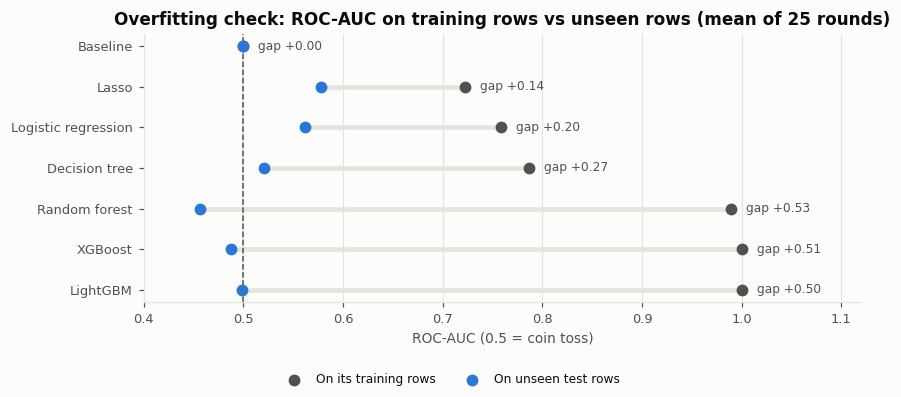

In [7]:
# ---- 5b. Training-row scores against test-row scores (same 25 rounds) ----------------------
by_model = scores.groupby("Model", sort=False)
train_vs_test = pd.DataFrame({
    "ROC-AUC on training rows": by_model["Train_ROC_AUC"].mean(),
    "ROC-AUC on test rows": by_model["ROC_AUC"].mean(),
    "Brier on training rows": by_model["Train_Brier"].mean(),
    "Brier on test rows": by_model["Brier"].mean(),
}).loc[MODEL_NAMES]
train_vs_test["ROC-AUC gap (train − test)"] = (train_vs_test["ROC-AUC on training rows"]
                                               - train_vs_test["ROC-AUC on test rows"])
train_vs_test["Brier gap (test − train)"] = (train_vs_test["Brier on test rows"]
                                             - train_vs_test["Brier on training rows"])
save_table(train_vs_test.round(4).reset_index(names="Model"), "5b_train_vs_test")
display(train_vs_test.round(3))

# Chart: one line per model from its training score (grey) to its test score (blue).
fig, ax = plt.subplots(figsize=(8, 3.6))
order = train_vs_test.index[::-1]
for i, m in enumerate(order):
    tr_v, te_v = train_vs_test.loc[m, "ROC-AUC on training rows"], train_vs_test.loc[m, "ROC-AUC on test rows"]
    ax.plot([te_v, tr_v], [i, i], color=GRID, linewidth=3, zorder=1)
    ax.scatter(tr_v, i, color=INK_2, s=45, zorder=2, label="On its training rows" if i == 0 else None)
    ax.scatter(te_v, i, color=BLUE, s=45, zorder=3, label="On unseen test rows" if i == 0 else None)
    ax.text(max(tr_v, te_v) + 0.015, i, f"gap {tr_v - te_v:+.2f}", va="center", color=INK_2, fontsize=8)
ax.axvline(0.5, color=INK_2, linestyle="--", linewidth=1)
ax.set_yticks(range(len(order)), order)
ax.set(title="Overfitting check: ROC-AUC on training rows vs unseen rows (mean of 25 rounds)",
       xlabel="ROC-AUC (0.5 = coin toss)", xlim=(0.4, 1.12))
ax.grid(axis="y", visible=False)
# Legend below the chart so it never covers a row.
fig.legend(*ax.get_legend_handles_labels(), loc="lower center", ncol=2, fontsize=8, frameon=False)
fig.tight_layout(rect=(0, 0.08, 1, 1))
save_chart(fig, "5b_train_vs_test")
plt.show()

## 6. Comparison chart

- **Left:** ROC-AUC. The dashed line at 0.5 is a coin toss.
- **Right:** Brier score, where lower is better. The dashed line is the baseline's 0.179.
- Dots are the means over 25 rounds, and the bars show ± 1 standard deviation.

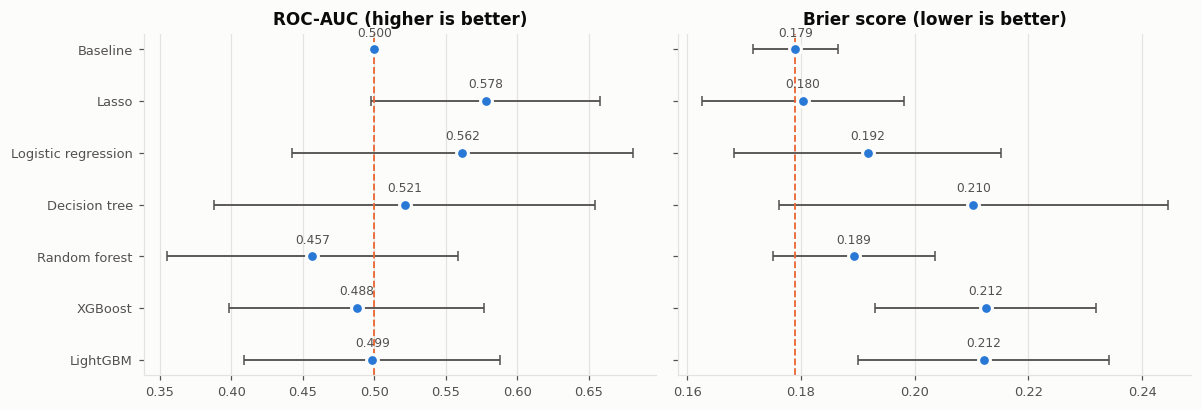

In [8]:
def comparison_chart(mean: pd.DataFrame, std: pd.DataFrame):
    """Two panels (separate scales, not a double axis): ROC-AUC and Brier, mean ± 1 std per model."""
    order = MODEL_NAMES[::-1]                       # baseline at the top when drawn bottom-up
    ypos = np.arange(len(order))
    fig, axes = plt.subplots(1, 2, figsize=(11, 3.8), sharey=True)
    for ax, measure, ref, title in [(axes[0], "ROC_AUC", 0.5, "ROC-AUC (higher is better)"),
                                    (axes[1], "Brier", mean.loc["Baseline", "Brier"], "Brier score (lower is better)")]:
        ax.errorbar(mean.loc[order, measure], ypos, xerr=std.loc[order, measure], fmt="none",
                    ecolor=INK_2, elinewidth=1.2, capsize=3)
        ax.scatter(mean.loc[order, measure], ypos, s=60, color=BLUE, edgecolor=SURFACE, linewidth=2, zorder=3)
        for i, v in enumerate(mean.loc[order, measure]):
            ax.text(v, i + 0.25, f"{v:.3f}", ha="center", color=INK_2, fontsize=8)
        ax.axvline(ref, color=ORANGE, linestyle="--", linewidth=1.2)
        ax.set(title=title)
        ax.grid(axis="y", visible=False)
    axes[0].set(yticks=ypos, yticklabels=order)
    fig.tight_layout()
    return fig


fig = comparison_chart(MEAN, STD)
save_chart(fig, "6_model_comparison")

## 7. What balancing would have done (comparison only, not used)

We decided **not** to balance the classes (M1-15). Here the same 25 rounds are rerun with "balanced" weights to show why.

```text
balanced weight of a row = rows ÷ (2 × rows in its class)
   failure: 144 ÷ (2 × ~34)  ≈ 2.1        success: 144 ÷ (2 × ~110) ≈ 0.65   → a failure counts ≈ 3.3× a success
```

Balancing teaches the model a world where about half of initiatives fail. Its P(Success) then drops below the real 77%, which would understate every Expected NPV in Task 3.

In [9]:
# Rerun every model except the baseline with balanced weights on the same 25 rounds.
balanced_models = {k: v for k, v in make_models().items() if k != "Baseline"}
scores_w, _, _ = run_cv(balanced_models, weighted=True)
_, MEAN_W, _ = summarise(scores_w)

compare = pd.DataFrame({
    "Mean P(Success), unweighted": MEAN.loc[MEAN_W.index, "Mean_P"],
    "Mean P(Success), balanced": MEAN_W["Mean_P"],
    "Brier, unweighted": MEAN.loc[MEAN_W.index, "Brier"],
    "Brier, balanced": MEAN_W["Brier"],
    "Failure recall, unweighted": MEAN.loc[MEAN_W.index, "Fail_recall"],
    "Failure recall, balanced": MEAN_W["Fail_recall"],
}).round(3)
save_table(compare.reset_index(), "7_balancing_comparison")
print(f"Real success rate: {y.mean():.3f} | baseline Brier: {MEAN.loc['Baseline', 'Brier']:.3f}")
display(compare)

Real success rate: 0.767 | baseline Brier: 0.179


,"Mean P(Success), unweighted","Mean P(Success), balanced","Brier, unweighted","Brier, balanced","Failure recall, unweighted","Failure recall, balanced"
Model,,,,,,
Lasso,0.748,0.506,0.180,0.252,0.736,0.985
Logistic regression,0.766,0.551,0.192,0.256,0.543,0.807
Decision tree,0.767,0.580,0.210,0.263,0.558,0.797
Random forest,0.761,0.620,0.189,0.212,0.431,0.939
XGBoost,0.785,0.668,0.212,0.238,0.339,0.587
LightGBM,0.794,0.685,0.212,0.237,0.330,0.559


## 8. Choose the model for Task 3 (decision M1-16)

**The rule:**
1. **Rank by Brier score.** The lowest is the most accurate probability.
2. **Drop any model whose ROC-AUC is clearly worse.** Here that means more than 0.05 below the best ROC-AUC.
3. **Prefer the simpler model when the difference is within luck.**
   - Compare each simpler model with the leader **round by round**: they faced the same 25 test sets.
   - Compute the 95% range of the mean Brier difference as mean ± 2.06 × (std of the differences ÷ √25). 2.06 is the t-value for 24 degrees of freedom.
   - If that range includes 0, the two models can't be told apart.
4. **Finance checks:** explainable to the Board, probabilities not biased up or down, few inputs, input directions that make financial sense, and stable across rounds. Step 8b puts all of them next to the ML scores for every model; step 10e checks the directions.

The baseline is not eligible: it carries no information about individual initiatives.

In [10]:
def choose_model(scores: pd.DataFrame, mean: pd.DataFrame, auc_margin: float = 0.05):
    """Apply the M1-16 rule and return (chosen model name, explanation table).

    scores : per-round scores (used for the paired comparison)
    mean   : per-model means
    """
    candidates = [m for m in MODEL_NAMES if m != "Baseline"]          # simplest → most complex
    best_auc = mean.loc[candidates, "ROC_AUC"].max()
    leader = mean.loc[candidates, "Brier"].idxmin()                    # step 1: lowest Brier
    lead_brier = scores[scores.Model == leader].set_index("Round")["Brier"]
    rows = []
    for m in candidates:
        b = scores[scores.Model == m].set_index("Round")["Brier"]
        diff = b - lead_brier                                          # paired: same 25 test sets
        half = 2.06 * diff.std(ddof=1) / np.sqrt(len(diff)) if m != leader else 0.0
        rows.append({"Model": m,
                     "Brier": mean.loc[m, "Brier"], "ROC_AUC": mean.loc[m, "ROC_AUC"],
                     "Brier minus leader": diff.mean(),
                     "95% range low": diff.mean() - half, "95% range high": diff.mean() + half,
                     "AUC not clearly worse": mean.loc[m, "ROC_AUC"] >= best_auc - auc_margin,
                     "Tied with leader": (diff.mean() - half) <= 0 <= (diff.mean() + half)})
    table = pd.DataFrame(rows).set_index("Model").round(4)
    eligible = table[(table["AUC not clearly worse"]) & (table["Tied with leader"])]
    chosen = eligible.index[0]                                         # simplest eligible (list is ordered)
    return chosen, leader, table


CHOSEN, LEADER, choice_table = choose_model(scores, MEAN)
save_table(choice_table.reset_index(), "8_model_choice")
display(choice_table)
print(f"Lowest Brier: {LEADER}  →  chosen (simplest model tied with it, AUC not clearly worse): {CHOSEN}")

,Brier,ROC_AUC,Brier minus leader,95% range low,95% range high,AUC not clearly worse,Tied with leader
Model,,,,,,,
Lasso,0.1804,0.5779,0.0000,0.0000,0.0000,True,True
Logistic regression,0.1917,0.5617,0.0113,0.0050,0.0177,True,False
Decision tree,0.2103,0.5212,0.0299,0.0165,0.0434,False,False
Random forest,0.1893,0.4568,0.0089,0.0041,0.0137,False,False
XGBoost,0.2125,0.4876,0.0321,0.0245,0.0397,False,False
LightGBM,0.2121,0.4986,0.0318,0.0225,0.0410,False,False


Lowest Brier: Lasso  →  chosen (simplest model tied with it, AUC not clearly worse): Lasso


## 8b. Why lasso and not the others: ML and finance scorecard

Step 8 applied the rule. This step shows **every model against every factor**, so the choice can be defended to a data scientist *and* to a finance committee.

**ML factors (from the 25 test rounds):**

| Factor | Formula / meaning | Why it matters for the decision |
| --- | --- | --- |
| Brier score | average of (P(Success) − actual)², lower is better | Task 3 computes Expected NPV = P(Success) × NPV, so an error in P becomes an error in money. A P that is 0.10 too high on a ₹100 lakh NPV overstates Expected NPV by ₹10 lakh |
| ROC-AUC | chance that a random success gets a higher P than a random failure (0.5 = coin toss) | The bank must **rank** initiatives to prioritise limited capital |
| Failure recall | failures flagged "at risk" ÷ all failures | Funding a failure loses the investment, the most expensive mistake, so catching failures matters most |
| Stability | standard deviation of ROC-AUC over the 25 rounds | A model that swings from round to round can't be relied on for next year's initiatives |

**Finance factors:**

| Factor | Formula / meaning | Why it matters |
| --- | --- | --- |
| Bias | average P(Success) − real success rate (0.767) | Above 0: the model is over-optimistic, so it overstates Expected NPV and pushes towards **over-funding**. Below 0: cautious. Near 0: honest |
| Inputs used | how many of the 26 inputs carry a non-zero weight | Fewer inputs: easier to explain, check and monitor, and less room to learn noise |
| Board can read it? | can the reason for a prediction be shown in a sentence? | The Board and model-risk reviewers must be able to see **why** an initiative is flagged before money is moved |
| Directions make sense | does each input push success the way finance theory expects? | Checked input by input in step 10e. A model that says "high risk raises success" would be rejected however well it scored |

The code builds the table from the numbers above (nothing typed by hand except the "Board can read it?" judgement), and writes each verdict from the same rules.

**Benchmark: the bank's own risk rating (decision M1-22).** The table also includes one row that is **not a candidate**:
- **What it is:** a **risk-rating-only model**, the simplest possible model, a lookup table.
- **How it works:** in each of the same 25 rounds, it learns the success rate of each risk level (Low, Medium, High) from the 144 training rows. It then predicts that rate for each of the 36 test initiatives.

```text
P(Success) of a test initiative = success rate of its risk level among the training rows
e.g. (whole-data figures) Low 57 ÷ 64 = 0.89,  Medium 50 ÷ 72 = 0.69,  High 31 ÷ 44 = 0.70
```

- **What it answers:** does the chosen model add anything **beyond the rating the bank already has**?
- **Why it can't be chosen:**
  - We built it *after* Task 1 and lasso had shown that the rating carries the signal. Its single input was picked by looking at the results, so its score is likely flattering.
  - Lasso, by contrast, was a pre-agreed candidate that chooses its inputs *inside* each training round, so its score is honest.
- **A second check:** the chosen model's ROC-AUC **within** each risk level. Can it tell successes from failures among initiatives with the same rating?

In [11]:
# ---- 8b. Scorecard: ML and finance factors for every model --------------------------------
N_INPUTS = len(NUM_COLS) + n_one_hot          # 17 number columns + 9 one-hot columns = 26 inputs
REAL_RATE = y.mean()                          # actual success rate, 138 ÷ 180 = 0.767

# How a Board member could read each model's reasoning (a judgement; explained in the text above).
BOARD_READABLE = {
    "Baseline": "Trivial: one number for everyone",
    "Lasso": "Yes: a few weights, read as odds ratios",
    "Logistic regression": "Partly: 26 weights to read",
    "Decision tree": "Yes: a few yes/no questions",
    "Random forest": "No: 300 trees, needs SHAP",
    "XGBoost": "No: 200 trees, needs SHAP",
    "LightGBM": "No: 200 trees, needs SHAP",
}

# Inputs each model actually uses: the baseline uses none; lasso drops some (average over the 25
# rounds, from step 5); every other model can use all 26.
inputs_used = {m: float(N_INPUTS) for m in MODEL_NAMES}
inputs_used["Baseline"] = 0.0
inputs_used["Lasso"] = round(float(lasso_kept.drop(columns="Penalty_C").sum(axis=1).mean()), 1)


def bias_effect(bias: float) -> str:
    """What a model's average over- or under-statement of P(Success) does to Expected NPV in Task 3.
    A margin of 0.01 (1 percentage point) separates a real bias from rounding noise."""
    if bias > 0.01:
        return "Overstates Expected NPV (risk of over-funding)"
    if bias < -0.01:
        return "Slightly understates Expected NPV (cautious)"
    return "Neutral"


def verdict(m: str) -> str:
    """A one-line reason for choosing or rejecting model m, built from the numbers.

    Uses choice_table from step 8 (Brier difference and its paired 95% range, AUC check)
    and MEAN from step 5 (ROC-AUC, average P)."""
    if m == "Baseline":
        return "Not eligible: same P(Success) for every initiative, so it cannot rank or flag any"
    if m == BENCH:
        return ("Benchmark, not a candidate: ties the chosen model, so the signal is the bank's own rating; "
                "built after seeing the results, so its score is likely flattering (M1-22)")
    if m == CHOSEN:
        return "Chosen: best Brier among real models (or tied and simplest), ROC-AUC not worse, readable, few inputs"
    row = choice_table.loc[m]
    reasons = []
    if not row["Tied with leader"]:
        reasons.append(f"Brier clearly worse (+{row['Brier minus leader']:.3f}; 95% range "
                       f"{row['95% range low']:.3f} to {row['95% range high']:.3f} does not include 0)")
    else:
        reasons.append("tied on Brier but more complex than the chosen model")
    if not row["AUC not clearly worse"]:
        reasons.append("ROC-AUC more than 0.05 below the best")
    if MEAN.loc[m, "ROC_AUC"] < 0.5:
        reasons.append("ranks worse than a coin toss")
    if MEAN.loc[m, "Mean_P"] - REAL_RATE > 0.01:
        reasons.append("over-optimistic P(Success)")
    if BOARD_READABLE[m].startswith("No"):
        reasons.append("a black box for the Board")
    return "Rejected: " + "; ".join(reasons)


# ---- Benchmark (M1-22): the bank's own risk rating as a lookup-table model ------------------
BENCH = "Risk rating only (benchmark)"
RISK = df["Risk_Rating"].astype(str).to_numpy()       # Low / Medium / High for every initiative


def risk_rating_benchmark():
    """Score the risk-rating lookup on the SAME 25 rounds as the candidate models.

    In each round: success rate of each risk level among the 144 training rows → predicted
    P(Success) for each of the 36 test rows = the rate of its level. Scored with score_round,
    exactly like the candidates. Returns (per-round scores, out-of-fold predictions per repeat)."""
    rows = []
    oof = np.full((N_REPEATS, len(y)), np.nan)
    for r, (tr, te) in enumerate(SPLITS):
        rates = pd.Series(y[tr]).groupby(RISK[tr]).mean()          # e.g. Low 0.89, Medium 0.69, High 0.70
        p = pd.Series(RISK[te]).map(rates).to_numpy()              # each test row gets its level's rate
        oof[r // N_SPLITS, te] = p
        rows.append({"Model": BENCH, "Round": r + 1, **score_round(y[te], p, y[tr].mean())})
    return pd.DataFrame(rows), oof


bench_scores, OOF[BENCH] = risk_rating_benchmark()
MEAN_ALL = pd.concat([MEAN, bench_scores.drop(columns=["Model", "Round"]).mean().to_frame(BENCH).T])
STD_ALL = pd.concat([STD, bench_scores.drop(columns=["Model", "Round"]).std().to_frame(BENCH).T])
ALL_ROWS = MODEL_NAMES + [BENCH]
inputs_used[BENCH] = 1.0
BOARD_READABLE[BENCH] = "Yes: one lookup by risk level"

# Paired comparison with the chosen model on the same 25 test sets (as in step 8).
diff = (bench_scores.set_index("Round")["Brier"]
        - scores[scores.Model == CHOSEN].set_index("Round")["Brier"])
half = 2.06 * diff.std(ddof=1) / np.sqrt(len(diff))
BENCH_VS_CHOSEN = (diff.mean(), diff.mean() - half, diff.mean() + half)
print(f"Benchmark minus {CHOSEN}, Brier: {BENCH_VS_CHOSEN[0]:+.4f} "
      f"(95% range {BENCH_VS_CHOSEN[1]:+.4f} to {BENCH_VS_CHOSEN[2]:+.4f}; "
      f"{'includes 0: a tie' if BENCH_VS_CHOSEN[1] <= 0 <= BENCH_VS_CHOSEN[2] else 'a real difference'})")

scorecard = pd.DataFrame({
    # ---- ML factors
    "Brier (lower better)": MEAN_ALL["Brier"].round(3),
    "ROC-AUC": MEAN_ALL["ROC_AUC"].round(3),
    "ROC-AUC std (stability)": STD_ALL["ROC_AUC"].round(3),
    "Failure recall": MEAN_ALL["Fail_recall"].round(3),
    # ---- finance factors
    "Average P(Success)": MEAN_ALL["Mean_P"].round(3),
    "Bias vs real 0.767": (MEAN_ALL["Mean_P"] - REAL_RATE).round(3),
    "Effect on Expected NPV": [bias_effect(b) for b in MEAN_ALL["Mean_P"] - REAL_RATE],
    "Inputs used": pd.Series(inputs_used),
    "Board can read it?": pd.Series(BOARD_READABLE),
}).loc[ALL_ROWS]
scorecard["Verdict"] = [verdict(m) for m in scorecard.index]
save_table(scorecard.reset_index(names="Model"), "8b_model_scorecard")

with pd.option_context("display.max_colwidth", None):    # show the full verdict text
    display(scorecard.drop(columns="Verdict"))
for m, v in scorecard["Verdict"].items():
    print(f"{m:<30} {v}")

# ---- Can the chosen model separate successes from failures WITHIN a risk level? ----------
p_oof_chosen = np.nanmean(OOF[CHOSEN], axis=0)         # out-of-fold P(Success), averaged over repeats
within = pd.DataFrame([
    {"Risk level": lvl, "Initiatives": int((RISK == lvl).sum()), "Failures": int(((RISK == lvl) & (y == 0)).sum()),
     f"{CHOSEN} ROC-AUC within the level": round(roc_auc_score(y[RISK == lvl], p_oof_chosen[RISK == lvl]), 3)}
    for lvl in ["Low", "Medium", "High"]]).set_index("Risk level")
save_table(within.reset_index(), "8b_within_risk_level")
print("ROC-AUC within each risk level (0.5 = coin toss; small groups, so read as a direction, not a precise value):")
display(within)

Benchmark minus Lasso, Brier: -0.0047 (95% range -0.0103 to +0.0010; includes 0: a tie)


,Brier (lower better),ROC-AUC,ROC-AUC std (stability),Failure recall,Average P(Success),Bias vs real 0.767,Effect on Expected NPV,Inputs used,Board can read it?
Baseline,0.179,0.500,0.000,0.000,0.767,-0.000,Neutral,0.0,Trivial: one number for everyone
Lasso,0.180,0.578,0.080,0.736,0.748,-0.019,Slightly understates Expected NPV (cautious),7.4,"Yes: a few weights, read as odds ratios"
Logistic regression,0.192,0.562,0.119,0.543,0.766,-0.001,Neutral,26.0,Partly: 26 weights to read
Decision tree,0.210,0.521,0.133,0.558,0.767,0.000,Neutral,26.0,Yes: a few yes/no questions
Random forest,0.189,0.457,0.102,0.431,0.761,-0.005,Neutral,26.0,"No: 300 trees, needs SHAP"
XGBoost,0.212,0.488,0.089,0.339,0.785,0.018,Overstates Expected NPV (risk of over-funding),26.0,"No: 200 trees, needs SHAP"
LightGBM,0.212,0.499,0.090,0.330,0.794,0.028,Overstates Expected NPV (risk of over-funding),26.0,"No: 200 trees, needs SHAP"
Risk rating only (benchmark),0.176,0.577,0.089,0.807,0.767,0.000,Neutral,1.0,Yes: one lookup by risk level


Baseline                       Not eligible: same P(Success) for every initiative, so it cannot rank or flag any
Lasso                          Chosen: best Brier among real models (or tied and simplest), ROC-AUC not worse, readable, few inputs
Logistic regression            Rejected: Brier clearly worse (+0.011; 95% range 0.005 to 0.018 does not include 0)
Decision tree                  Rejected: Brier clearly worse (+0.030; 95% range 0.017 to 0.043 does not include 0); ROC-AUC more than 0.05 below the best
Random forest                  Rejected: Brier clearly worse (+0.009; 95% range 0.004 to 0.014 does not include 0); ROC-AUC more than 0.05 below the best; ranks worse than a coin toss; a black box for the Board
XGBoost                        Rejected: Brier clearly worse (+0.032; 95% range 0.025 to 0.040 does not include 0); ROC-AUC more than 0.05 below the best; ranks worse than a coin toss; over-optimistic P(Success); a black box for the Board
LightGBM                       Rejec

,Initiatives,Failures,Lasso ROC-AUC within the level
Risk level,,,
Low,64,7,0.231
Medium,72,22,0.536
High,44,13,0.278


## 8c. In rupees: how much failed capital each model's flag would have caught

The Board does not decide on Brier scores. It decides on **money**. The finance question is:

> *If we had used this model's "at risk" flag to decide which initiatives get a closer review, how much of the money that was lost on failed initiatives would we have looked at in time?*

**Terms:**
- **Failed capital** = the Initial_Investment (₹ lakh) of initiatives that actually failed. That is money committed to projects that did not deliver.
- **Flag** = out-of-fold P(Success) below the base rate (0.767): "less likely to succeed than a typical initiative". Out-of-fold means each initiative is scored by a model that never saw it (step 2), so this is an honest replay.

```text
Share of failed capital caught = Σ investment of failed initiatives that were flagged ÷ Σ investment of all failed initiatives
Failure rate among flagged     = flagged initiatives that failed ÷ all flagged initiatives
Capital sent to review         = Σ investment of all flagged initiatives   (the review workload, in ₹)
```

**How to read it:**
- A useful flag catches a **large share of failed capital** while sending **less than all** the capital to review.
- Flagging everything would catch 100%, so the fair measure is the **capital lift**:

  ```text
  Capital lift = share of failed capital caught ÷ share of all capital reviewed
  1.0 = no better than picking projects to review at random;  above 1 = the flag finds failures;  below 1 = it points at the safe ones
  ```
- The **failure rate among flagged** initiatives should be clearly *higher* than among the rest. If it is lower, the flag points the wrong way: it would send reviewers to the safe projects.
- The baseline gives every initiative almost the same P(Success), so any flags it raises come from tiny round-to-round differences in the training base rate. They are meaningless, so they are shown as "n/a".
- The **risk-rating benchmark** (step 8b) is included, in aqua on the chart. Its flag is simply "Medium or High risk". If it does as well as the chosen model, the flag's value comes from the bank's own rating.

This is **evidence for the Board**, not a new selection rule. The model was already chosen by the rule in step 8 (decision M1-16). The flag is for **review intensity**, not automatic rejection. Funding decisions are made in Task 3 with NPV.

Total capital ₹283.4 crore; failed capital ₹65.5 crore (23% of all capital, in 42 failed initiatives)


,Flagged initiatives,Capital sent to review (₹ crore),Share of all capital reviewed,Failed capital caught (₹ crore),Share of failed capital caught,Failure rate among flagged,Failure rate among not flagged,Capital lift (caught ÷ reviewed),Flag points the right way?
Baseline,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,n/a
Lasso,106.0,168.439,0.594,49.390,0.754,0.302,0.135,1.269,Yes
Logistic regression,87.0,140.035,0.494,38.244,0.584,0.276,0.194,1.182,Yes
Decision tree,91.0,144.572,0.510,35.979,0.549,0.264,0.202,1.077,Yes
Random forest,98.0,155.989,0.550,33.218,0.507,0.204,0.268,0.921,No
XGBoost,71.0,104.510,0.369,25.115,0.383,0.211,0.248,1.040,No
LightGBM,67.0,101.568,0.358,27.028,0.413,0.224,0.239,1.151,No
Risk rating only (benchmark),116.0,184.844,0.652,56.327,0.860,0.302,0.109,1.318,Yes


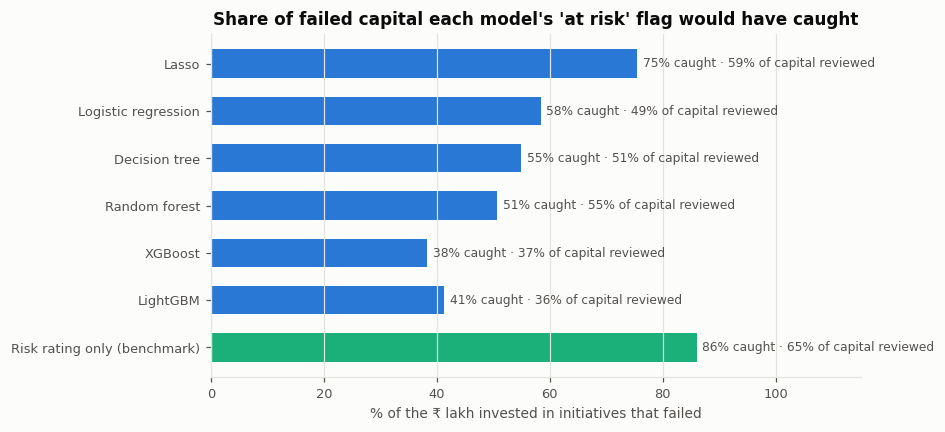

In [12]:
# ---- 8c. The rupee view of each model's "at risk" flag ------------------------------------
invest = df["Initial_Investment"].to_numpy()          # ₹ lakh committed to each initiative
failed = y == 0                                       # True for initiatives that actually failed
failed_capital = invest[failed].sum()                 # ₹ lakh lost to failures in total
cutoff_all = y.mean()                                 # 0.767: the same cut-off as the At_Risk column in step 12


def capital_view(model_name: str) -> dict:
    """Replay one model's out-of-fold flag on the 180 initiatives and measure it in rupees.

    p    = out-of-fold P(Success) averaged over the 5 repeats (each initiative scored by a model
           that never saw it), from step 5.
    flag = p below the base rate.
    Returns counts, ₹ crore (1 crore = 100 lakh) and rates for the Board table."""
    p = np.nanmean(OOF[model_name], axis=0)
    flag = p < cutoff_all
    caught = invest[flag & failed].sum()               # failed capital the flag would have pointed at
    return {
        "Flagged initiatives": int(flag.sum()),
        "Capital sent to review (₹ crore)": invest[flag].sum() / 100,
        "Share of all capital reviewed": invest[flag].sum() / invest.sum(),
        "Failed capital caught (₹ crore)": caught / 100,
        "Share of failed capital caught": caught / failed_capital,
        "Failure rate among flagged": (flag & failed).sum() / max(flag.sum(), 1),
        "Failure rate among not flagged": (~flag & failed).sum() / max((~flag).sum(), 1),
    }


capital = pd.DataFrame({m: capital_view(m) for m in ALL_ROWS}).T            # candidates + the benchmark
# Lift: how much better than reviewing the same amount of capital at random. Random review of 59% of
# the capital would catch about 59% of the failed capital, so lift = 1. Above 1 = the flag targets
# failures; below 1 = it targets the safe projects.
capital["Capital lift (caught ÷ reviewed)"] = (capital["Share of failed capital caught"]
                                               / capital["Share of all capital reviewed"])
capital["Flag points the right way?"] = np.where(
    capital["Failure rate among flagged"] > capital["Failure rate among not flagged"], "Yes", "No")
num_cols = capital.columns.drop("Flag points the right way?")
capital[num_cols] = capital[num_cols].astype(float).round(3)
capital.loc["Baseline", num_cols] = np.nan             # baseline flags are noise (see text above): left blank
capital.loc["Baseline", "Flag points the right way?"] = "n/a"
save_table(capital.reset_index(names="Model"), "8c_capital_view")
print(f"Total capital ₹{invest.sum() / 100:.1f} crore; failed capital ₹{failed_capital / 100:.1f} crore "
      f"({failed_capital / invest.sum():.0%} of all capital, in {failed.sum()} failed initiatives)")
display(capital)

# Chart: share of failed capital caught, one bar per real model (higher is better).
real = [m for m in MODEL_NAMES if m != "Baseline"] + [BENCH]
shares = capital.loc[real, "Share of failed capital caught"].astype(float) * 100
reviewed = capital.loc[real, "Share of all capital reviewed"].astype(float) * 100
fig, ax = plt.subplots(figsize=(8.5, 4))
# Candidates in blue; the benchmark in aqua so it reads as a reference line, not a competitor.
ax.barh(real[::-1], shares[::-1], color=[AQUA if m == BENCH else BLUE for m in real[::-1]], height=0.6)
for i, m in enumerate(real[::-1]):
    ax.text(shares[m] + 1, i, f"{shares[m]:.0f}% caught · {reviewed[m]:.0f}% of capital reviewed",
            va="center", color=INK_2, fontsize=8)
ax.set(title="Share of failed capital each model's 'at risk' flag would have caught",
       xlabel="% of the ₹ lakh invested in initiatives that failed", xlim=(0, 115))
ax.grid(axis="y", visible=False)
fig.tight_layout()
save_chart(fig, "8c_capital_caught")
plt.show()

## 9. Better than luck? (shuffled-label check)

**Idea:**
1. Shuffle the success labels at random, which destroys any real link between inputs and success.
2. Re-run the model with 5-fold cross-validation.
3. Repeat 100 times.

If the real ROC-AUC is rarely matched by shuffled labels, the model has found a real signal.

```text
p-value = (number of shuffles with ROC-AUC ≥ real ROC-AUC + 1) ÷ (100 + 1)
```

We run it for the chosen model and for plain logistic regression with all 26 inputs.

,Real ROC-AUC (5-fold),Shuffled 95th percentile,p-value
Lasso,0.583,0.626,0.168
Logistic regression,0.576,0.621,0.178


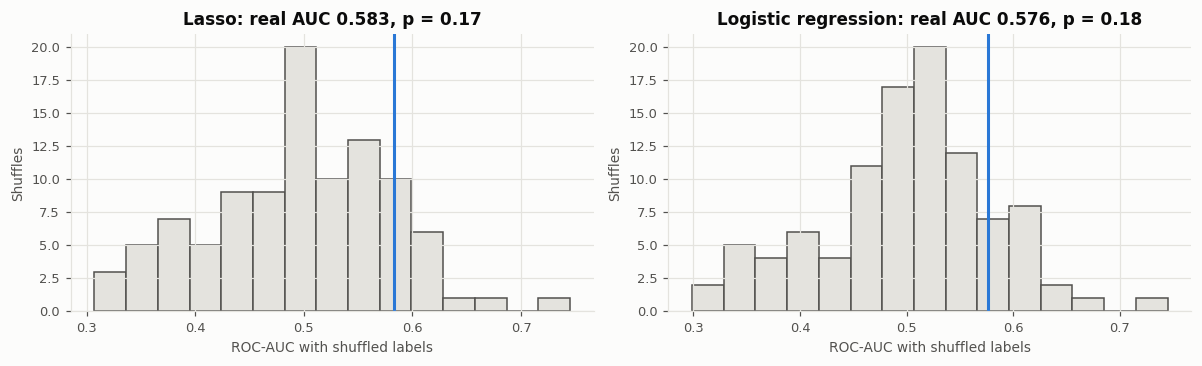

In [13]:
def shuffled_label_check(name: str, n_shuffles: int = 100):
    """Real 5-fold ROC-AUC vs ROC-AUC after shuffling the labels n_shuffles times.
    Uses scikit-learn's permutation_test_score (same Pipeline, so no leakage)."""
    pipe = make_models()[name]
    real, shuffled, p = permutation_test_score(
        pipe, X, y, scoring="roc_auc", cv=StratifiedKFold(5, shuffle=True, random_state=SEED),
        n_permutations=n_shuffles, random_state=SEED, n_jobs=1)
    return real, shuffled, p


luck = {}
for name in dict.fromkeys([CHOSEN, "Logistic regression"]):           # dict.fromkeys removes a duplicate
    luck[name] = shuffled_label_check(name)

fig, axes = plt.subplots(1, len(luck), figsize=(5.5 * len(luck), 3.4), squeeze=False)
for ax, (name, (real, shuffled, p)) in zip(axes[0], luck.items()):
    ax.hist(shuffled, bins=15, color=GRID, edgecolor=INK_2)
    ax.axvline(real, color=BLUE, linewidth=2)
    ax.set(title=f"{name}: real AUC {real:.3f}, p = {p:.2f}", xlabel="ROC-AUC with shuffled labels",
           ylabel="Shuffles")
fig.tight_layout()
save_chart(fig, "9_shuffled_label_check")
luck_table = pd.DataFrame({n: {"Real ROC-AUC (5-fold)": r, "Shuffled 95th percentile": np.percentile(s, 95),
                               "p-value": p} for n, (r, s, p) in luck.items()}).T.round(3)
save_table(luck_table.reset_index(names="Model"), "9_shuffled_label_check")
display(luck_table)

## 10. Explainability: which characteristics make success more likely?

Explanations come from **one fit of each model on all 180 initiatives**. These fits are only for explanation and are never scored; every score above came from the 25 test rounds.

**10a. Logistic regression, as odds ratios.**

```text
Odds of success = P ÷ (1 − P)             e.g. P = 0.8 → odds = 4 ("4 to 1")
Odds ratio (OR) of an input = e^b         b = its weight; inputs are scaled, so "per 1 standard deviation"
OR > 1: raises the odds of success;  OR < 1: lowers them;  OR = 1.25 → odds × 1.25 per 1 std increase
```

**10b. Lasso.**
- Which inputs it keeps, and in how many of the 25 rounds. An input kept in nearly every round is a stable signal; one kept rarely is noise.
- Its weights on the full fit.

**10c. SHAP (SHapley Additive exPlanations).** For one initiative, SHAP splits the model's prediction into a contribution from each input:

```text
prediction (log-odds) = average prediction + Σ SHAP value of each input
```

A positive SHAP value pushes that initiative's success up; a negative one pushes it down. It comes from game theory (Shapley values): each input's fair share of the difference between this prediction and the average one.
- The **summary chart** shows every initiative as a dot per input; the colour is the input's value, from low (blue) to high (red).
- The **waterfall chart** shows one initiative's prediction built up input by input.

**Finance check (M1-16):** do the directions make sense? For example, Low risk and a higher ROI spread should not *lower* success.

,Weight b,Odds ratio e^b
Business_Unit = Corporate Banking,-0.663,0.515
Risk_Rating = Medium,-0.406,0.666
Risk_Rating = High,-0.339,0.712
NPV_3yr,-0.245,0.783
Revenue_Year2,-0.198,0.820
Cash_Return_Pct,-0.190,0.827
CF2,-0.179,0.836
GDP_Growth,-0.153,0.858
Competition_Index,-0.136,0.873
Operating_Cost,-0.128,0.880


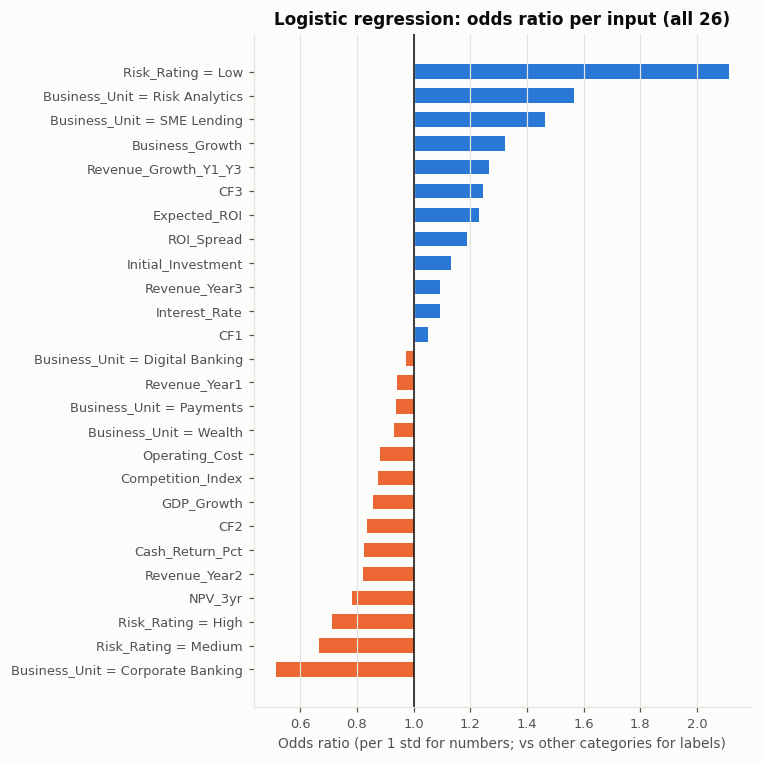

In [14]:
# ---- One fit on all 180 rows per explained model (explanation only, never scored) ---------
FULL = {name: make_models()[name].fit(X, y) for name in dict.fromkeys([CHOSEN, "Logistic regression", "Lasso"])}


def prepared_frame(pipe: Pipeline) -> pd.DataFrame:
    """The 180 initiatives after the pipeline's preparation step, with readable column names."""
    prep = pipe.named_steps["prep"]
    return pd.DataFrame(prep.transform(X), columns=[clean_name(f) for f in prep.get_feature_names_out()])


# ---- 10a. Logistic regression odds ratios ------------------------------------------------
lr = FULL["Logistic regression"]
lr_coef = pd.Series(lr.named_steps["model"].coef_[0], index=prepared_frame(lr).columns)
odds = pd.DataFrame({"Weight b": lr_coef, "Odds ratio e^b": np.exp(lr_coef)}).sort_values("Odds ratio e^b")
save_table(odds.reset_index(names="Input"), "10a_logistic_odds_ratios")

fig, ax = plt.subplots(figsize=(7, 7))
colours = [BLUE if v > 1 else ORANGE for v in odds["Odds ratio e^b"]]
ax.barh(odds.index, odds["Odds ratio e^b"] - 1, left=1, color=colours, height=0.6)   # bars start at OR = 1
ax.axvline(1, color=INK, linewidth=1)
ax.set(title="Logistic regression: odds ratio per input (all 26)",
       xlabel="Odds ratio (per 1 std for numbers; vs other categories for labels)")
ax.grid(axis="y", visible=False)
fig.tight_layout()
save_chart(fig, "10a_logistic_odds_ratios")
display(odds.round(3))

Lasso kept on average 7.4 of 26 inputs per round; inputs kept on the full fit: 9


,Kept in share of 25 rounds,Full-fit weight,Full-fit odds ratio
Risk_Rating = Low,1.00,0.878,2.407
Business_Growth,0.80,0.154,1.166
Business_Unit = Corporate Banking,0.68,-0.245,0.783
Revenue_Growth_Y1_Y3,0.68,0.066,1.068
GDP_Growth,0.68,-0.024,0.976
Expected_ROI,0.60,0.099,1.104
Competition_Index,0.60,-0.041,0.960
Cash_Return_Pct,0.48,-0.033,0.967
NPV_3yr,0.40,-0.039,0.962
ROI_Spread,0.32,0.000,1.000


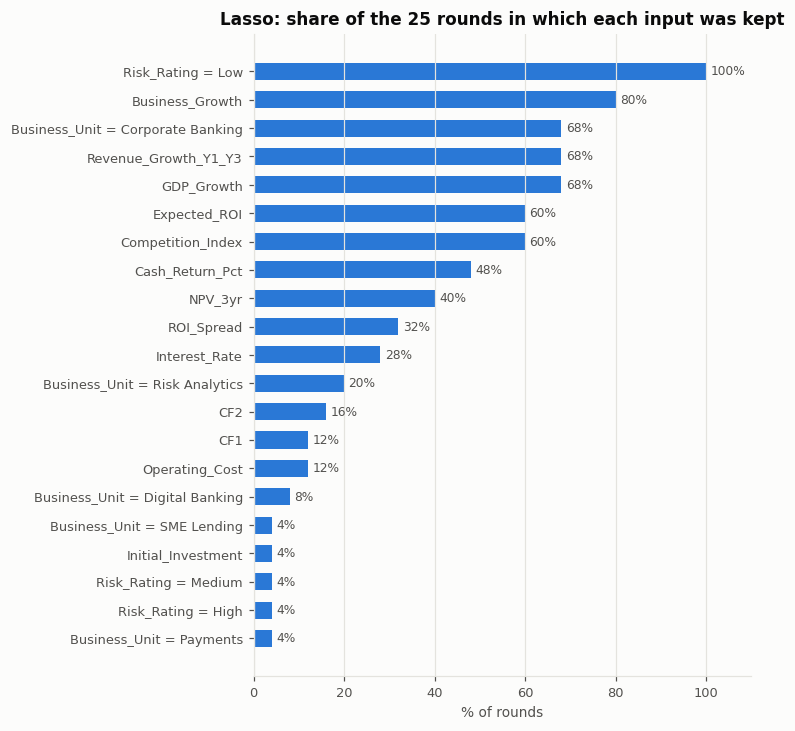

In [15]:
# ---- 10b. Lasso: inputs kept across 25 rounds, and full-fit weights -----------------------
kept_share = lasso_kept.drop(columns="Penalty_C").mean().sort_values(ascending=False)   # share of rounds kept
lasso_full = FULL["Lasso"]
lasso_coef = pd.Series(lasso_full.named_steps["model"].coef_[0], index=prepared_frame(lasso_full).columns)
lasso_table = pd.DataFrame({"Kept in share of 25 rounds": kept_share,
                            "Full-fit weight": lasso_coef.reindex(kept_share.index),
                            "Full-fit odds ratio": np.exp(lasso_coef.reindex(kept_share.index))}).round(3)
save_table(lasso_table.reset_index(names="Input"), "10b_lasso_inputs")
print(f"Lasso kept on average {lasso_kept.drop(columns='Penalty_C').sum(axis=1).mean():.1f} of 26 inputs per round; "
      f"inputs kept on the full fit: {int((lasso_coef != 0).sum())}")

top = kept_share[kept_share > 0]
fig, ax = plt.subplots(figsize=(7, max(2.5, 0.32 * len(top))))
ax.barh(top.index[::-1], top.values[::-1] * 100, color=BLUE, height=0.6)
for i, v in enumerate(top.values[::-1] * 100):
    ax.text(v + 1, i, f"{v:.0f}%", va="center", color=INK_2, fontsize=8)
ax.set(title="Lasso: share of the 25 rounds in which each input was kept", xlabel="% of rounds", xlim=(0, 110))
ax.grid(axis="y", visible=False)
fig.tight_layout()
save_chart(fig, "10b_lasso_inputs")
display(lasso_table[lasso_table["Kept in share of 25 rounds"] > 0])

### 10b-ii. How lasso works inside: how it chooses, ranks and switches off inputs

Lasso is the model we chose, so here is exactly what it does with the 26 inputs.

**1. What it minimises.** scikit-learn's lasso logistic regression finds the weights b that make this as small as possible:

```text
Σ |bⱼ|   +   C × Σᵢ log-lossᵢ
penalty      how badly the model fits the training rows (log-loss of each row i, summed)

log-lossᵢ = −[ yᵢ × ln(pᵢ) + (1 − yᵢ) × ln(1 − pᵢ) ]        pᵢ = P(Success) for row i
C = 1 ÷ λ:  small C (= big λ) → the penalty dominates → few inputs survive
```

It is a trade: every input "costs" its absolute weight, and is only worth keeping if it cuts the fitting error by more than it costs.

**2. Why the inputs are scaled first** (z = (x − mean) ÷ standard deviation).
- The penalty compares weight *sizes*.
- Without scaling, an input measured in ₹ lakh (hundreds) would need a tiny weight, and one measured in % a large one, for the same effect. Lasso would then unfairly switch off the % inputs.
- After scaling, every input is "per 1 standard deviation", so the competition is fair.

**3. How it decides, input by input (coordinate descent).** Lasso does **not** rotate or combine the inputs. Rotating would be PCA, which builds new mixed inputs nobody can name. Lasso keeps the original, named inputs, which is why the Board can read it. The solver **cycles through the weights one at a time**:

```text
repeat until nothing changes:
    for each input j in turn:
        hold every other weight fixed
        g_j = Σᵢ (yᵢ − pᵢ) × xᵢⱼ      ← how strongly input j lines up with what the model still gets wrong
        if |g_j| × C ≤ 1:   bⱼ = 0   ← not worth its cost: switched off
        else:               move bⱼ to the value that best balances fit against cost
```

- An input stays at **exactly zero** unless it explains enough of the *remaining* error to pay for itself.
- "Remaining" matters. Once Expected_ROI is in, ROI_Spread (Expected_ROI − Interest_Rate) carries almost nothing new, so it stays switched off.
- That is why lasso keeps **one input out of a group of near-duplicates** (CF1/CF2/CF3 vs the revenues, Expected_ROI vs ROI_Spread) instead of splitting the weight across all of them, as ridge logistic regression does.

**4. How it ranks and prioritises inputs: the lasso path.** Start with a huge penalty (all weights 0) and slowly relax it:
- the input that enters **first** is the one the data supports most strongly;
- the next one is the strongest of the rest, given the first; and so on.

The **order of entry is lasso's priority ranking**. The chart below draws the path on all 180 initiatives (for explanation only). Each line is one input's weight as the penalty relaxes from left to right. The dashed line is the penalty actually chosen most often in the 25 rounds.

**5. How strong the penalty is: chosen, not guessed.**
- In each round, an inner 5-fold cross-validation on the 144 training rows tries 10 values of C and keeps the one with the best Brier score (nested cross-validation, step 3).
- The table below counts which C won in the 25 rounds.
- Technical note: the solver (liblinear) also penalises the intercept, so at the tiniest C values every prediction is 0.5. Those values never win.

**6. How we read the result.**
- Each kept weight b becomes an odds ratio e^b, "per 1 standard deviation" (step 10a).
- An input that enters early on the path *and* is kept in most of the 25 rounds is a **trustworthy driver**.
- An input that enters late *or* is kept rarely is **noise**.

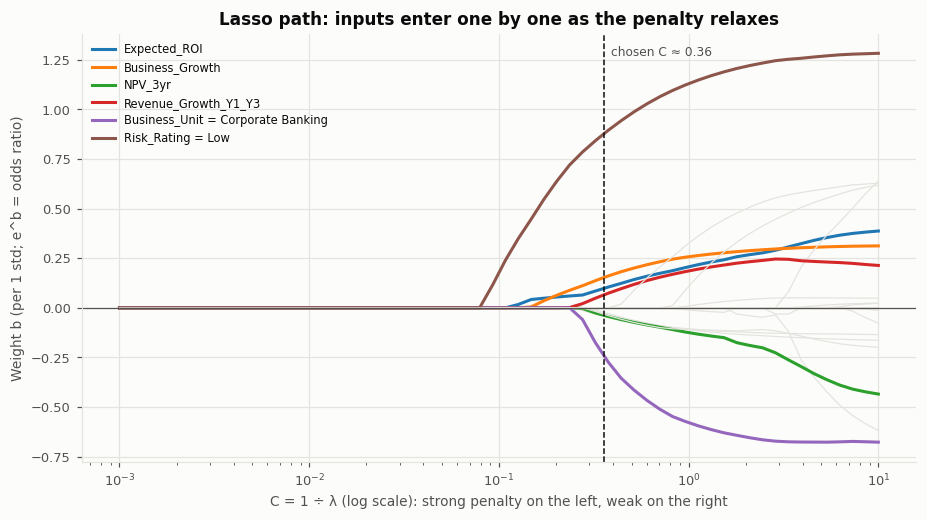

Order in which inputs enter the lasso path (first = strongest priority):


,Entry order,Enters at C,Kept in % of 25 rounds
Risk_Rating = Low,1,0.092,100.0
Expected_ROI,2,0.126,60.0
Business_Growth,3,0.148,80.0
Revenue_Growth_Y1_Y3,4,0.236,68.0
NPV_3yr,5,0.276,40.0
Business_Unit = Corporate Banking,6,0.276,68.0
Competition_Index,7,0.276,60.0
Cash_Return_Pct,8,0.322,48.0
GDP_Growth,9,0.322,68.0
Business_Unit = Risk Analytics,10,0.441,20.0


Penalty C chosen by the inner cross-validation in the 25 rounds (value: number of rounds):


,Rounds
Penalty_C,
0.3594,24
2.7826,1


In [16]:
# ---- 10b-ii. The lasso path: the order in which inputs enter as the penalty relaxes --------
lasso_prep = FULL["Lasso"].named_steps["prep"]                     # preparation learned on all 180 rows
Xp = prepared_frame(FULL["Lasso"])                                  # 180 × 26 scaled / one-hot inputs
C_GRID = np.logspace(-3, 1, 60)                                     # 60 penalty values from strong to weak


def lasso_path(C_values: np.ndarray) -> pd.DataFrame:
    """Fit lasso at each C (explanation only, all 180 rows) and return the weights: one row per C, one column per input."""
    rows = []
    for c in C_values:
        m = LogisticRegression(penalty="l1", solver="liblinear", C=c, max_iter=5000, random_state=SEED).fit(Xp, y)
        rows.append(m.coef_[0])
    return pd.DataFrame(rows, index=C_values, columns=Xp.columns)


path = lasso_path(C_GRID)
# Entry point of each input = the smallest C (strongest penalty) at which its weight is no longer 0.
entered = path.ne(0)
entry_C = entered.idxmax().where(entered.any())                     # NaN if it never enters on this grid
order = entry_C.dropna().sort_values()
entry_table = pd.DataFrame({
    "Entry order": range(1, len(order) + 1),
    "Enters at C": order.round(3),
    "Kept in % of 25 rounds": (kept_share.reindex(order.index) * 100).round(0),
}, index=order.index)
save_table(entry_table.reset_index(names="Input"), "10b2_lasso_entry_order")

# Which penalty won the inner cross-validation in each of the 25 rounds.
chosen_C = lasso_kept["Penalty_C"].round(4).value_counts().sort_index()
typical_C = float(lasso_kept["Penalty_C"].median())

fig, ax = plt.subplots(figsize=(8.5, 4.8))
first = list(order.index[:6])                                      # label the first 6 inputs to enter
for col in path.columns:
    if col in first:
        ax.plot(path.index, path[col], linewidth=2, label=col)
    else:
        ax.plot(path.index, path[col], linewidth=0.8, color=GRID)  # later inputs drawn quietly
ax.axvline(typical_C, color=INK, linestyle="--", linewidth=1)
ax.text(typical_C * 1.08, ax.get_ylim()[1] * 0.92, f"chosen C ≈ {typical_C:.2f}", color=INK_2, fontsize=8)
ax.axhline(0, color=INK_2, linewidth=0.8)
ax.set_xscale("log")
ax.set(title="Lasso path: inputs enter one by one as the penalty relaxes",
       xlabel="C = 1 ÷ λ (log scale): strong penalty on the left, weak on the right",
       ylabel="Weight b (per 1 std; e^b = odds ratio)")
ax.legend(fontsize=7.5, frameon=False, loc="upper left")
fig.tight_layout()
save_chart(fig, "10b2_lasso_path")
plt.show()

print("Order in which inputs enter the lasso path (first = strongest priority):")
display(entry_table.head(12))
print("Penalty C chosen by the inner cross-validation in the 25 rounds (value: number of rounds):")
display(chosen_C.to_frame("Rounds"))

Background dataset has 180 samples but max_samples=100. Subsampling to 100 samples for SHAP value computation. To use all samples, set max_samples=180 when initializing the masker.


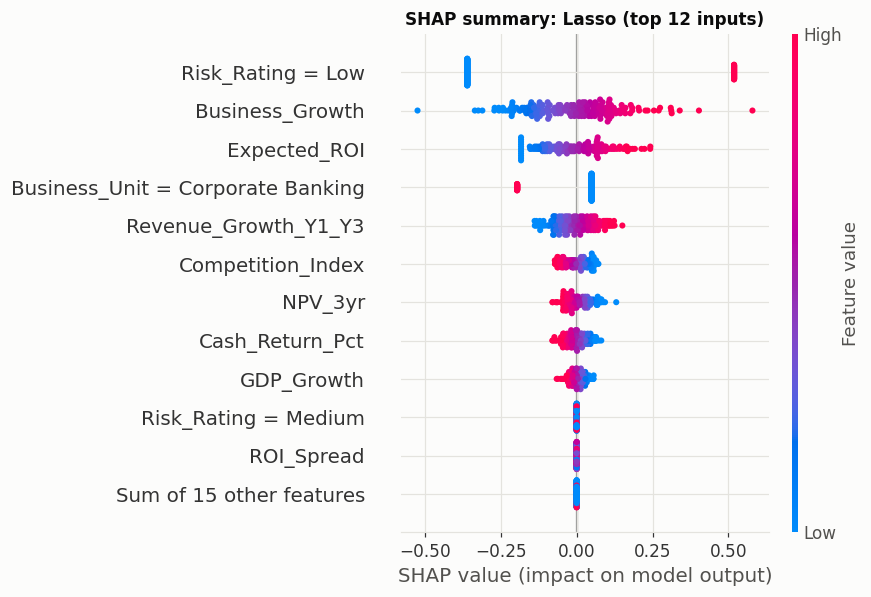

Lasso: top 8 inputs by mean |SHAP|


,Mean |SHAP|
Risk_Rating = Low,0.4164
Business_Growth,0.1210
Expected_ROI,0.0815
Business_Unit = Corporate Banking,0.0776
Revenue_Growth_Y1_Y3,0.0563
Competition_Index,0.0357
NPV_3yr,0.0314
Cash_Return_Pct,0.0262


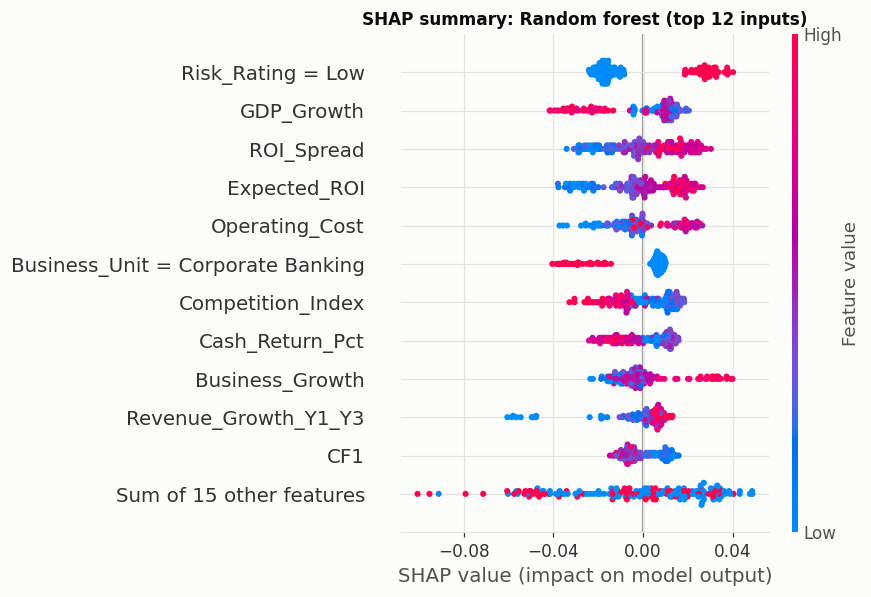

Random forest: top 8 inputs by mean |SHAP|


,Mean |SHAP|
Risk_Rating = Low,0.0210
GDP_Growth,0.0147
ROI_Spread,0.0140
Expected_ROI,0.0133
Operating_Cost,0.0113
Business_Unit = Corporate Banking,0.0112
Competition_Index,0.0110
Cash_Return_Pct,0.0102


In [17]:
# ---- 10c. SHAP for the chosen model and the best tree model -------------------------------
TREE_MODELS = ["Decision tree", "Random forest", "XGBoost", "LightGBM"]
BEST_TREE = MEAN.loc[TREE_MODELS, "Brier"].idxmin()
if BEST_TREE not in FULL:
    FULL[BEST_TREE] = make_models()[BEST_TREE].fit(X, y)


def shap_explanation(name: str) -> shap.Explanation:
    """SHAP values for all 180 initiatives from the full fit of one model.
    Linear models: LinearExplainer (exact for a linear model, in log-odds).
    Tree models:   TreeExplainer (exact for trees). Random forest / decision tree return
                   one set per class; we keep class 1 (success)."""
    pipe = FULL[name]
    data = prepared_frame(pipe)
    model = pipe.named_steps["model"]
    if name in TREE_MODELS:
        explanation = shap.TreeExplainer(model)(data)
    else:
        explanation = shap.LinearExplainer(model, data)(data)
    if explanation.values.ndim == 3:                       # (rows, inputs, classes) → keep success
        explanation = explanation[:, :, 1]
    return explanation


SHAP = {name: shap_explanation(name) for name in dict.fromkeys([CHOSEN, BEST_TREE])}
for name, expl in SHAP.items():
    plt.figure()
    np.random.seed(SEED)                        # SHAP places overlapping dots at random: fixed so reruns draw the same chart
    shap.plots.beeswarm(expl, max_display=12, show=False)
    plt.title(f"SHAP summary: {name} (top 12 inputs)", fontsize=11, fontweight="bold")
    fig = plt.gcf()
    fig.set_size_inches(8, 5.5)
    fig.axes[0].xaxis.set_major_locator(plt.MaxNLocator(5))     # few enough ticks that the numbers don't overlap
    fig.tight_layout()
    save_chart(fig, f"10c_shap_summary_{name.lower().replace(' ', '_')}")
    plt.show()
    # Mean |SHAP| = average size of each input's push, a simple importance ranking.
    imp = pd.Series(np.abs(expl.values).mean(axis=0), index=expl.feature_names).sort_values(ascending=False)
    save_table(imp.round(4).reset_index().rename(columns={"index": "Input", 0: "Mean |SHAP|"}),
               f"10c_shap_importance_{name.lower().replace(' ', '_')}")
    print(f"{name}: top 8 inputs by mean |SHAP|")
    display(imp.head(8).round(4).to_frame("Mean |SHAP|"))

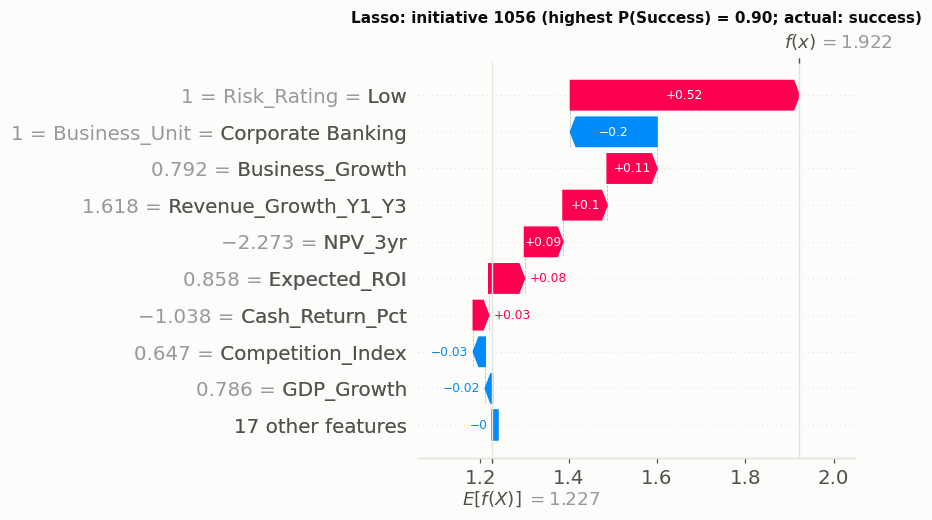

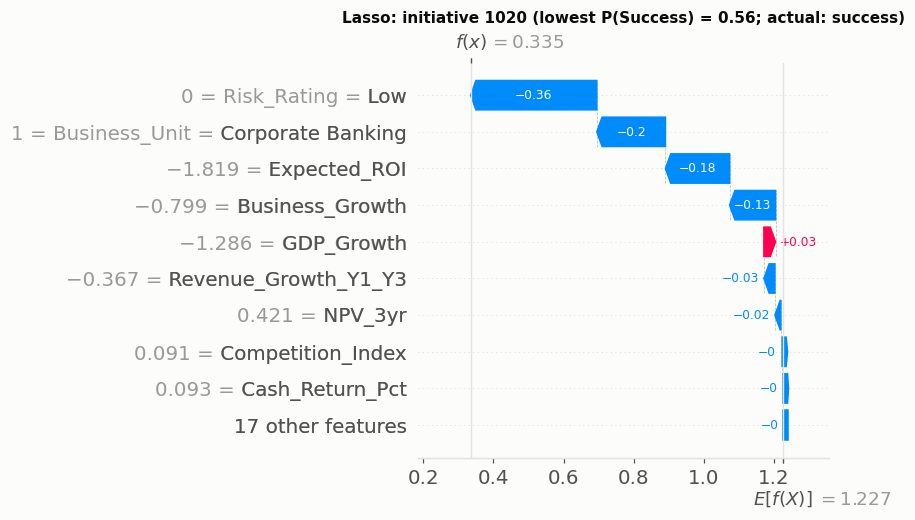

In [18]:
# ---- 10d. One strong and one weak initiative (waterfall charts for the chosen model) ------
p_chosen = np.nanmean(OOF[CHOSEN], axis=0)                 # out-of-fold P(Success), averaged over repeats
hi, lo = int(np.argmax(p_chosen)), int(np.argmin(p_chosen))
for idx, label in [(hi, "highest"), (lo, "lowest")]:
    plt.figure()
    shap.plots.waterfall(SHAP[CHOSEN][idx], max_display=10, show=False)
    fig = plt.gcf()
    fig.set_size_inches(8, 4.8)
    fig.axes[0].grid(False)                                        # no grid lines through the numbers
    for txt in fig.axes[0].texts:
        txt.set_fontsize(8)                                        # the numbers fit inside their bars
    plt.title(f"{CHOSEN}: initiative {ids[idx]} ({label} P(Success) = {p_chosen[idx]:.2f}; "
              f"actual: {'success' if y[idx] == 1 else 'failure'})", fontsize=10, fontweight="bold")
    fig.tight_layout()
    save_chart(fig, f"10d_waterfall_{label}")
    plt.show()

### 10e. What drives success: one ranked table, with the finance meaning

The question in the brief is *which characteristics make an initiative more likely to succeed*. Steps 10a–10c answered it three ways. Here they are combined into **one ranked table**. An input we can trust:
- **matters:** a large average SHAP value in the chosen model;
- **is stable:** lasso keeps it in most of the 25 rounds. 80% or more is "stable", 50–79% "moderate", below 50% "weak, likely noise";
- **agrees across models:** the same direction in lasso and plain logistic regression, and a high rank in the tree model's SHAP;
- **makes financial sense:** its direction matches what finance theory expects. Low risk should raise success; more competition should lower it.

**How to read an odds ratio as a change in P(Success).** An initiative at the average success rate has odds 0.767 ÷ 0.233 ≈ 3.3. If an input has OR = 2.4:

```text
new odds = 3.3 × 2.4 ≈ 7.9      new P = odds ÷ (1 + odds) = 7.9 ÷ 8.9 ≈ 0.89
```

So a Low risk rating moves a typical initiative from about 77% to about 89% chance of success. That matches Task 1, where Low-risk initiatives succeeded 89% of the time.

**What "maximising success" can and cannot mean here:**
- **Levers the bank controls:**
  - the **risk profile** it accepts, or reduces by piloting and phased funding;
  - how strong an **ROI case** it demands;
  - how closely it **reviews units** with lower success, such as Corporate Banking.
- **Context it can only select for or time:** business growth, competition, the economy. It can't change them, but can favour initiatives where they are good.
- **Caveats:**
  - These are **associations, not causes.** Relabelling an initiative "Low risk" does not make it safer.
  - The overall signal is weak (ROC-AUC about 0.58), so even the strongest driver moves P(Success) only moderately.
  - Inputs marked "weak, likely noise" should not drive any decision.

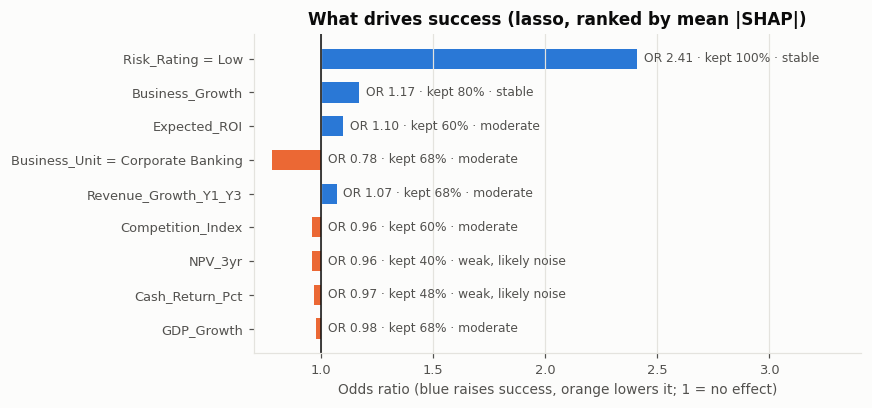

,Rank,Mean |SHAP| (lasso),Kept in % of rounds,Lasso odds ratio,Logistic odds ratio,Rank in Random forest SHAP,Direction,Logistic agrees?,Finance expects,Makes financial sense?,Signal,What it means for the bank
Risk_Rating = Low,1,0.416,100.0,2.41,2.11,1,Raises success,Yes,Raises,Yes,Stable,"Strongest lever: favour low-risk initiatives, or de-risk (pilot, phased funding) before approving"
Business_Growth,2,0.121,80.0,1.17,1.32,9,Raises success,Yes,Raises,Yes,Stable,Initiatives in fast-growing businesses succeed more often; weigh the unit's growth outlook
Expected_ROI,3,0.081,60.0,1.10,1.23,4,Raises success,Yes,Raises,Yes,Moderate,A higher planned return goes with success; ask for a credible ROI case
Business_Unit = Corporate Banking,4,0.078,68.0,0.78,0.52,6,Lowers success,Yes,No clear prior,n/a,Moderate,Succeeds less often than other units; extra review and tighter milestones
Revenue_Growth_Y1_Y3,5,0.056,68.0,1.07,1.27,10,Raises success,Yes,Raises,Yes,Moderate,Plans with faster revenue growth succeed slightly more often
Competition_Index,6,0.036,60.0,0.96,0.87,7,Lowers success,Yes,Lowers,Yes,Moderate,Crowded markets lower success slightly; check competitive position
NPV_3yr,7,0.031,40.0,0.96,0.78,14,Lowers success,Yes,Raises,No,"Weak, likely noise","Tiny, unstable effect: a high 3-year NPV on paper does not predict execution success"
Cash_Return_Pct,8,0.026,48.0,0.97,0.83,8,Lowers success,Yes,Raises,No,"Weak, likely noise","Tiny, unstable effect: strong paper cash returns do not predict success"
GDP_Growth,9,0.019,68.0,0.98,0.86,2,Lowers success,Yes,Raises,No,Moderate,Tiny effect against expectation; the unit's own growth matters more than the economy


In [19]:
# ---- 10e. What drives success: one ranked table from all three explanations ----------------
# Direction finance theory expects for each input: +1 raises success, −1 lowers it.
# Inputs not listed have no clear expected direction (e.g. one business unit vs the others).
EXPECTED_SIGN = {
    "Risk_Rating = Low": +1, "Risk_Rating = Medium": -1, "Risk_Rating = High": -1,
    "Business_Growth": +1, "GDP_Growth": +1, "Expected_ROI": +1, "ROI_Spread": +1,
    "Revenue_Growth_Y1_Y3": +1, "NPV_3yr": +1, "Cash_Return_Pct": +1,
    "Competition_Index": -1, "Interest_Rate": -1, "Operating_Cost": -1,
}
# What each input means for the bank, in one line (used for the inputs the chosen model keeps).
MEANING = {
    "Risk_Rating = Low": "Strongest lever: favour low-risk initiatives, or de-risk (pilot, phased funding) before approving",
    "Risk_Rating = Medium": "Medium risk succeeds less often than Low",
    "Risk_Rating = High": "High risk succeeds less often than Low",
    "Business_Growth": "Initiatives in fast-growing businesses succeed more often; weigh the unit's growth outlook",
    "Expected_ROI": "A higher planned return goes with success; ask for a credible ROI case",
    "Business_Unit = Corporate Banking": "Succeeds less often than other units; extra review and tighter milestones",
    "Revenue_Growth_Y1_Y3": "Plans with faster revenue growth succeed slightly more often",
    "Competition_Index": "Crowded markets lower success slightly; check competitive position",
    "GDP_Growth": "Tiny effect against expectation; the unit's own growth matters more than the economy",
    "NPV_3yr": "Tiny, unstable effect: a high 3-year NPV on paper does not predict execution success",
    "Cash_Return_Pct": "Tiny, unstable effect: strong paper cash returns do not predict success",
    "ROI_Spread": "Return above the funding cost; weak once Expected_ROI is in the model",
    "Interest_Rate": "Funding cost; weak effect",
}


def mean_abs_shap(expl: shap.Explanation) -> pd.Series:
    """Average size of each input's push on the prediction over the 180 initiatives."""
    return pd.Series(np.abs(expl.values).mean(axis=0), index=expl.feature_names)


def signal_label(kept: float) -> str:
    """Stability label from the share of the 25 lasso rounds that kept the input."""
    if kept >= 0.8:
        return "Stable"
    if kept >= 0.5:
        return "Moderate"
    return "Weak, likely noise"


if "Lasso" not in SHAP:                                   # lasso's SHAP is needed even if it was not chosen
    SHAP["Lasso"] = shap_explanation("Lasso")
lasso_imp = mean_abs_shap(SHAP["Lasso"])
tree_rank = mean_abs_shap(SHAP[BEST_TREE]).rank(ascending=False).astype(int)   # 1 = most important

drivers = pd.DataFrame({
    "Mean |SHAP| (lasso)": lasso_imp,
    "Kept in % of rounds": kept_share * 100,
    "Lasso odds ratio": np.exp(lasso_coef),
    "Logistic odds ratio": odds["Odds ratio e^b"],
    f"Rank in {BEST_TREE} SHAP": tree_rank,
})
drivers = drivers[drivers["Mean |SHAP| (lasso)"] > 0].sort_values("Mean |SHAP| (lasso)", ascending=False)

sign = np.sign(lasso_coef.reindex(drivers.index))                      # +1 raises, −1 lowers success
expected = pd.Series(EXPECTED_SIGN).reindex(drivers.index)
drivers["Direction"] = np.where(sign > 0, "Raises success", "Lowers success")
drivers["Logistic agrees?"] = np.where(np.sign(np.log(drivers["Logistic odds ratio"])) == sign, "Yes", "No")
drivers["Finance expects"] = expected.map({1: "Raises", -1: "Lowers"}).fillna("No clear prior")
drivers["Makes financial sense?"] = np.where(expected.isna(), "n/a", np.where(expected == sign, "Yes", "No"))
drivers["Signal"] = [signal_label(k / 100) for k in drivers["Kept in % of rounds"]]
drivers["What it means for the bank"] = [MEANING.get(i, "") for i in drivers.index]
drivers.insert(0, "Rank", range(1, len(drivers) + 1))
drivers = drivers.round({"Mean |SHAP| (lasso)": 3, "Kept in % of rounds": 0,
                         "Lasso odds ratio": 2, "Logistic odds ratio": 2})
save_table(drivers.reset_index(names="Input"), "10e_success_drivers")

# Chart: lasso odds ratio per driver, bars starting at OR = 1; blue raises success, orange lowers it.
fig, ax = plt.subplots(figsize=(8, max(2.5, 0.42 * len(drivers))))
plot = drivers.iloc[::-1]                                    # largest driver at the top
ors = plot["Lasso odds ratio"]
ax.barh(plot.index, ors - 1, left=1, color=[BLUE if v > 1 else ORANGE for v in ors], height=0.6)
for i, (v, k, sig) in enumerate(zip(ors, plot["Kept in % of rounds"], plot["Signal"])):
    ax.text(max(v, 1) + 0.03, i, f"OR {v:.2f} · kept {k:.0f}% · {sig.lower()}", va="center", color=INK_2, fontsize=8)
ax.axvline(1, color=INK, linewidth=1)
ax.set(title="What drives success (lasso, ranked by mean |SHAP|)",
       xlabel="Odds ratio (blue raises success, orange lowers it; 1 = no effect)",
       xlim=(min(0.7, ors.min() - 0.05), ors.max() + 1.0))
ax.grid(axis="y", visible=False)
fig.tight_layout()
save_chart(fig, "10e_success_drivers")
plt.show()

with pd.option_context("display.max_colwidth", None):
    display(drivers)

#### 10e (continued). The finance and business reasoning behind each driver, for the Board

A Board will ask *why* each driver matters, not just how big its odds ratio is. Evidence below comes from Task 1 (`outputs/task1/`) and from this task. Where the data cannot prove a cause, the reasoning is marked as a **hypothesis to check**.

| Driver | Why it makes business sense | Evidence in our data | What the Board can do |
| --- | --- | --- | --- |
| **Low risk rating** (raises success; odds × 2.4) | Fewer unknowns: proven technology, known customers, smaller execution and regulatory surprises. A risk rating is the bank's own summary of "what could go wrong" | Low risk: 89% succeed, against 69% (Medium) and 70% (High). Task 1 chi-square p = 0.014. Low risk also has the highest median Expected ROI (12.0%, against 8.3% for High). There's no trade-off here: Low risk is safer **and** promises more | Screen on risk first. Medium/High-risk projects need a closer look before money is committed, for example a pilot (how Task 3 treats them: Task 3 report §2) |
| **Business_Growth** (raises; odds × 1.17 per 1 std) | A growing business gives the initiative a demand tailwind: more customers and more cross-selling, and mistakes are easier to absorb | Business_Growth is the strongest link to Expected ROI in Task 1 (r = 0.56). Kept by lasso in 80% of rounds | Prioritise initiatives that ride a growing line of business. Ask sponsors for evidence of the growth assumption |
| **Expected_ROI** (raises; odds × 1.10 per 1 std) | A higher planned return is a **margin of safety**: a project that promises 14% can absorb cost overruns or slower take-up and still pay off; one promising 6% cannot | Enters the lasso path second. Logistic OR 1.23 | Ask for a credible ROI case with downside scenarios. Treat very thin returns as fragile |
| **Corporate Banking** (lowers; odds × 0.78) | **Hypothesis to check:** corporate initiatives tend to be large, bespoke and dependent on a few big clients, with long sales cycles. That makes them harder to deliver | Lowest success of all units (63%; 95% range 46–77%) and the most capital (₹62.3 crore). Its share of High-risk projects (17%) is among the lowest (only SME Lending's is lower), so the risk rating does **not** explain its weakness. It looks unit-specific. The unit difference is not statistically firm in Task 1 (p = 0.36) | Don't cut the unit. Review its initiatives more closely (tighter milestones, post-implementation reviews) and find the cause before the next budget round |
| **Revenue growth Y1→Y3** (raises slightly) | A plan whose revenue builds up shows evidence of real demand, not a one-off | Odds × 1.07 per 1 std; kept in 68% of rounds | Check that the growth path is backed by pipeline or pilot data |
| **Competition_Index** (lowers slightly) | Crowded markets squeeze prices and slow customer take-up | Odds × 0.96 per 1 std; kept in 60% of rounds | Ask how the initiative will win against rivals; weigh the market's crowding |
| **NPV_3yr, Cash_Return_Pct, GDP_Growth** (tiny, against intuition) | 3-year NPV is negative for 172 of 180 initiatives. It counts only 3 years of cash, so it measures **payback speed**, not execution quality. Cash return and NPV are sponsors' projections, and optimistic plans are common. GDP affects every unit alike | Kept in only 40–48% (NPV, cash return) or with an odds ratio of 0.98 (GDP): noise | Don't read a strong-looking business case as a sign it will succeed. That is why Task 3 values the outcome (NPV) **separately** from the chance of success (P) |

**Board message in one paragraph.** Whether an initiative succeeds depends mostly on **its risk and the health of the business it sits in**, not on how good its spreadsheet looks. The bank's controllable levers are:
- which risk it accepts, and how it stages funding for riskier projects;
- how hard it tests the ROI case;
- how closely it supervises the unit with the weakest record.

The model's "at risk" flag (step 8c) tells reviewers where to look first. Task 3 then decides with money: Expected NPV.

## 11. Are the probabilities right? (reliability chart)

1. Sort the 180 initiatives by their out-of-fold P(Success).
2. Cut them into 5 groups of 36.
3. For each group, compare the average predicted P(Success) with the share that actually succeeded.

If the probabilities are right, the points lie on the diagonal: initiatives given about 80% should succeed about 80% of the time. Each bar shows the 95% range of the actual share (Wilson). We would recalibrate only if the points were clearly off the diagonal.

In [20]:
from statsmodels.stats.proportion import proportion_confint

groups = pd.qcut(p_chosen, 5, labels=False, duplicates="drop")     # 5 groups by predicted P
rel = (pd.DataFrame({"p": p_chosen, "y": y, "g": groups})
       .groupby("g").agg(predicted=("p", "mean"), actual=("y", "mean"), n=("y", "size"), wins=("y", "sum")))
rel[["low", "high"]] = [proportion_confint(w, n, method="wilson") for w, n in zip(rel.wins, rel.n)]
save_table(rel.round(3).reset_index(drop=True), "11_reliability")

fig, ax = plt.subplots(figsize=(5, 4.5))
lims = (min(rel.predicted.min(), rel.low.min()) - 0.05, 1.0)
ax.plot(lims, lims, color=INK_2, linestyle="--", linewidth=1)                 # perfect calibration
ax.errorbar(rel.predicted, rel.actual, yerr=[rel.actual - rel.low, rel.high - rel.actual],
            fmt="none", ecolor=INK_2, capsize=3)
ax.scatter(rel.predicted, rel.actual, s=60, color=BLUE, edgecolor=SURFACE, linewidth=2, zorder=3)
ax.set(xlim=lims, ylim=lims, xlabel="Average predicted P(Success)", ylabel="Actual success rate",
       title=f"Reliability: {CHOSEN} (5 groups of 36)")
fig.tight_layout()
save_chart(fig, "11_reliability")
display(rel[["predicted", "actual", "low", "high", "n"]].round(3))

,predicted,actual,low,high,n
g,,,,,
0,0.643,0.750,0.589,0.862,36
1,0.693,0.667,0.503,0.798,36
2,0.739,0.694,0.531,0.820,36
3,0.804,0.944,0.819,0.985,36
4,0.860,0.778,0.619,0.883,36


## 12. Save P(Success) for Task 3

- `outputs/task2/FINAL_M1_T2_success_probability.csv` holds Initiative_ID, P_Success (the chosen model's out-of-fold prediction, averaged over 5 repeats) and At_Risk (P_Success below the 77% base rate). **Task 3 reads this file** (decision P-15).
- `outputs/task2/oof_all_models.csv` holds the same for every model, for reference.
- `outputs/task2/key_numbers.json` holds the headline figures quoted in `reports/task2_report.md`.

In [21]:
base_rate = y.mean()
p_success = pd.DataFrame({"Initiative_ID": ids,
                          "P_Success": np.round(p_chosen, 4),
                          "At_Risk": (p_chosen < base_rate).astype(int),
                          "Model": CHOSEN})
p_success.to_csv(OUT_DIR / "FINAL_M1_T2_success_probability.csv", index=False)

oof_all = pd.DataFrame({"Initiative_ID": ids, "Historical_Success": y,
                        **{m: np.round(np.nanmean(OOF[m], axis=0), 4) for m in MODEL_NAMES}})
oof_all.to_csv(OUT_DIR / "oof_all_models.csv", index=False)

flagged = p_success.At_Risk == 1
key = {
    "chosen_model": CHOSEN,
    "lowest_brier_model": LEADER,
    "best_tree_model": BEST_TREE,
    "baseline_brier": round(float(MEAN.loc["Baseline", "Brier"]), 4),
    "chosen_brier": round(float(MEAN.loc[CHOSEN, "Brier"]), 4),
    "chosen_roc_auc": round(float(MEAN.loc[CHOSEN, "ROC_AUC"]), 3),
    "chosen_roc_auc_std": round(float(STD.loc[CHOSEN, "ROC_AUC"]), 3),
    "chosen_fail_recall": round(float(MEAN.loc[CHOSEN, "Fail_recall"]), 3),
    "shuffled_label_p": {m: round(float(v[2]), 3) for m, v in luck.items()},
    "p_success_range": [round(float(p_chosen.min()), 3), round(float(p_chosen.max()), 3)],
    "at_risk_count": int(flagged.sum()),
    "at_risk_actual_failure_rate": round(float((y[flagged.to_numpy()] == 0).mean()), 3),
    "not_at_risk_actual_failure_rate": round(float((y[~flagged.to_numpy()] == 0).mean()), 3),
    "lasso_inputs_kept_mean": round(float(lasso_kept.drop(columns="Penalty_C").sum(axis=1).mean()), 1),
    "benchmark_risk_only": {
        "roc_auc": round(float(MEAN_ALL.loc[BENCH, "ROC_AUC"]), 3),
        "brier": round(float(MEAN_ALL.loc[BENCH, "Brier"]), 4),
        "brier_minus_chosen": [round(float(v), 4) for v in BENCH_VS_CHOSEN],
        "capital_lift": round(float(capital.loc[BENCH, "Capital lift (caught ÷ reviewed)"]), 3),
        "chosen_capital_lift": round(float(capital.loc[CHOSEN, "Capital lift (caught ÷ reviewed)"]), 3),
    },
}
(OUT_DIR / "key_numbers.json").write_text(json.dumps(key, indent=2), encoding="utf-8")
display(p_success.describe().round(3))
print(json.dumps(key, indent=2))

,Initiative_ID,P_Success,At_Risk
count,180.000,180.000,180.000
mean,1090.500,0.748,0.589
std,52.106,0.080,0.493
min,1001.000,0.557,0.000
25%,1045.750,0.684,0.000
50%,1090.500,0.742,1.000
75%,1135.250,0.822,1.000
max,1180.000,0.896,1.000


{
  "chosen_model": "Lasso",
  "lowest_brier_model": "Lasso",
  "best_tree_model": "Random forest",
  "baseline_brier": 0.179,
  "chosen_brier": 0.1804,
  "chosen_roc_auc": 0.578,
  "chosen_roc_auc_std": 0.08,
  "chosen_fail_recall": 0.736,
  "shuffled_label_p": {
    "Lasso": 0.168,
    "Logistic regression": 0.178
  },
  "p_success_range": [
    0.557,
    0.895
  ],
  "at_risk_count": 106,
  "at_risk_actual_failure_rate": 0.302,
  "not_at_risk_actual_failure_rate": 0.135,
  "lasso_inputs_kept_mean": 7.4,
  "benchmark_risk_only": {
    "roc_auc": 0.577,
    "brier": 0.1757,
    "brier_minus_chosen": [
      -0.0047,
      -0.0103,
      0.001
    ],
    "capital_lift": 1.318,
    "chosen_capital_lift": 1.269
  }
}


## 13. What the results say: the ML case, the finance case, and the decision

The numbers are from the run saved in `outputs/task2/`. Full write-up with charts: `reports/task2_report.md`. The case is written for a Board that reads both ML and finance, so each side gets equal weight.

### 13.1 The ML case

1. **What we tested.** Seven models, each trained and tested on the **same 25 rounds** of repeated stratified 5-fold cross-validation (step 2). Every score comes from initiatives the model never saw, so it is honest, and the comparison is paired.
2. **The signal is weak.**
   - Best ROC-AUC is 0.578 ± 0.080 (lasso; 0.5 = coin toss). It beats a coin toss in 21 of the 25 rounds.
   - Its Brier score (0.180) is statistically tied with saying 77% for everyone (0.179; paired 95% range −0.005 to +0.008).
   - The shuffled-label check gives p = 0.17 (step 9).
3. **Why lasso wins on ML grounds** (steps 8, 8b):
   - the lowest Brier score of the real models; every other model is significantly worse round by round;
   - the highest ROC-AUC and the best failure recall (catches about 74% of failures);
   - the most stable linear model (ROC-AUC spread ±0.08, against ±0.12 for plain logistic regression).
4. **Benchmark: the bank's own risk rating** (step 8b, M1-22).
   - A lookup model that predicts each risk level's success rate **ties lasso**: ROC-AUC 0.577 against 0.578; Brier 0.176 against 0.180, a statistical tie.
   - Within each risk level, lasso ranks no better than chance.
   - **So the predictive signal in this data is the risk rating.** Lasso found it, and showed that the other 25 inputs add nothing reliable.
5. **Why the flexible models lose.**
   - Random forest, XGBoost and LightGBM score ROC-AUC 0.46–0.50 (chance).
   - With about 34 failures per training round they learn noise.
   - Lasso fights noise by design (step 10b-ii): it keeps about 7 of 26 inputs, shrinks their weights, and keeps one of each group of near-duplicates.
6. **No balancing** (step 7). Balancing pulls the average P(Success) to 0.51–0.69 when the real rate is 0.77, and worsens every Brier score. That confirms M1-15.
7. **Calibration.** The reliability chart (step 11) shows no clear miscalibration, so the probabilities can be used as they are.

### 13.2 The finance case

1. **The money at stake.** ₹283.5 crore was committed across 180 initiatives. ₹65.5 crore (23%) went into initiatives that failed.
2. **Lasso's flag targets that money** (step 8c):
   - Replayed honestly (out-of-fold), its "at risk" flag would have sent 59% of the capital to closer review and caught about **75% of the failed capital**. That is a **capital lift of about 1.3**: 27% better than reviewing the same amount at random.
   - Flagged initiatives failed 30% of the time, against 13.5% for the rest (chi-square p = 0.015).
   - Random forest and XGBoost/LightGBM flags point the **wrong way**: their flagged initiatives fail *less* often than the unflagged ones.
   - The **risk-rating benchmark's flag** ("Medium or High risk") does at least as well: it catches 86% of the failed capital while reviewing 65% (lift 1.32). The flag's value comes from the bank's own rating.
3. **Honest probabilities protect Expected NPV** (step 8b).
   - Task 3 computes Expected NPV = P(Success) × NPV.
   - Lasso's average P is 0.748 against the real 0.767: slightly cautious.
   - XGBoost and LightGBM average 0.785 and 0.794. They would **overstate** Expected NPV and push towards over-funding.
4. **Explainable and governable.**
   - About 7 named inputs, each read as an odds ratio, with no hidden combinations (lasso does not rotate inputs).
   - A Board member or model-risk reviewer can see why an initiative is flagged.
   - It is cheap to monitor: re-check the same few inputs each budget round.
5. **The drivers make business sense** (step 10e):
   - **Low risk** moves a typical initiative from about 77% to about 89% success (odds × 2.4; Task 1 also showed 89%);
   - **growing businesses** and a **stronger ROI case** (a margin of safety) help;
   - **Corporate Banking** lags for reasons its risk rating does not explain (to investigate);
   - **competition** hurts slightly.

   A strong NPV *on paper* does **not** predict success. Task 3 therefore values the outcome (NPV) separately from the chance of success (P).

### 13.3 The decision

**Lasso's out-of-fold P(Success) goes to Task 3** (M1-16, M1-19). It ranges from 0.56 to 0.90, with a median of 0.74.
- **Why lasso and not the benchmark that ties it:**
  - Lasso was a pre-agreed candidate that picks its inputs *inside* each training round, so its score is honest.
  - The benchmark was built *after* the results showed that the rating carries the signal, so its score is likely flattering (M1-22).
  - Task 3 shows the Board the rating-only decisions as a sensitivity run (M1-23).
- **ML grounds:** the only real model that is at least as accurate as all the others.
- **Finance grounds:** honest, explainable, and its flag points reviewers at the money that was actually lost.

**Caution for Task 3:**
- The probabilities are no more accurate than a flat 77% on Brier.
- So Task 3 should also show Expected NPV with P(Success) = 0.77 for every initiative (sensitivity, M1-20). The Board can then see which Fund / Review / Reject decisions depend on the model.
- The flag guides **review effort**. It does not reject projects on its own.